## 1. Problem Statement

Formula 1 is a ~US$ 3 billion-a-year sport in which teams spend up to the US$ 135 million budget cap
chasing performance gains measured in thousandths of a second. Every year, the governing body (FIA) changes
the technical and sporting regulations with explicit goals: *closer racing, more overtaking, less
dominance by a single team*. Teams, broadcasters and the sport's owner make multi-million-dollar decisions
based on beliefs such as *"the race is won in qualifying"*, *"the car matters more than the driver"*, or
*"home crowds lift drivers"*.

**This study tests those beliefs with data.** Using every World Championship race from 1950 to 2025, we
quantify what actually determines race outcomes, evaluate whether major regulation changes achieved their
stated goals, and build a regression model that predicts a driver's finishing position from information
available *before the race starts*.

## 3. Dataset Description

| Item | Details |
|---|---|
| **Source** | Jolpica F1 open database, the community successor to the Ergast Developer API (https://github.com/jolpica/jolpica-f1) |
| **Coverage** | Every Formula 1 World Championship race, **1950 – 2025** (the 2026 season is still in progress and is excluded) |
| **Format** | Relational database exported as 11 linked CSV tables (a star schema around race results) |
| **Size** | ≈ 26,000 driver race entries, ≈ 1,150 races, ≈ 870 drivers, ≈ 210 constructors, 77 circuits, ≈ 12,000 pit stops |

**Tables used**

| Table | Grain (one row per…) | Key attributes |
|---|---|---|
| `sessionentry` | driver per session | grid, position, points, status, detail, laps completed, is_classified |
| `session` | session (practice / qualifying / race) | type, round, scheduled laps, is_cancelled |
| `round` | Grand Prix weekend | race name, date, circuit, season |
| `season` | championship year | year |
| `roundentry` | car entry per weekend | car number, team-driver link |
| `teamdriver` | driver contract per season | driver, team |
| `team` | constructor | name, nationality |
| `driver` | driver | name, nationality, date of birth |
| `circuit` | track | name, country, latitude, longitude |
| `pitstop` | pit stop | duration, stop number |
| `driverchampionship` | driver standing after each session | championship position, points |

**Target / key variables:** finishing `position` (regression target), `grid` (starting position), race
outcome (`status`: finished, lapped, accident, mechanical failure, disqualified, did not start).

---
## 2. Library Import


In [1]:
# -----------------------------------------------------------------------------
# 1. Standard libraries for data manipulation
# -----------------------------------------------------------------------------
import os
import warnings
from math import ceil
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# 2. Data visualization libraries
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

# -----------------------------------------------------------------------------
# 3. Statistical and Machine Learning libraries
# -----------------------------------------------------------------------------
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pio.renderers.default = 'plotly_mimetype+notebook_connected'

DATA_DIR, FIG_DIR, OUT_DIR = 'data', 'figures', 'outputs'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

ERA_ORDER = ['1950–79 Pioneer', '1980–99 Turbo & Aero', '2000–13 V10/V8', '2014–21 Hybrid', '2022–25 Ground-effect']
ERA_COLORS = dict(zip(ERA_ORDER, ['#9e9e9e', '#6a8caf', '#2e5f8a', '#e10600', '#ff8c42']))
F1_RED = '#e10600'

def show(name):
    """Helper function to save and display Matplotlib plots cleanly."""
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('All libraries loaded successfully.')


All libraries loaded successfully.


### Statistical Testing Helper Functions

In [2]:
ALPHA = 0.05

def verdict(p):
    """Decision Rule: Reject H0 if p < alpha, else Fail to Reject H0."""
    return 'Reject H0' if p < ALPHA else 'Fail to reject H0'

def magnitude(value, small, medium, large):
    """Label practical effect size magnitude."""
    v = abs(value)
    return 'negligible' if v < small else 'small' if v < medium else 'medium' if v < large else 'large'

def cohen_h(p1, p2):
    """Effect size for difference between two proportions (A/B testing)."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def cohen_d(a, b):
    """Standardised difference between two group means (Two-sample t-test effect size)."""
    a, b = np.asarray(a), np.asarray(b)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

def cramers_v(table):
    """Association strength for Chi-square contingency table ."""
    chi2 = stats.chi2_contingency(table)[0]
    n = np.asarray(table).sum()
    return np.sqrt(chi2 / (n * (min(np.shape(table)) - 1)))

def rank_biserial(u, n1, n2):
    """Rank-biserial effect size for two-sample comparisons."""
    return 1 - 2 * u / (n1 * n2)

def wilson(k, n):
    """Wilson score confidence interval for proportions."""
    return proportion_confint(k, n, alpha=ALPHA, method='wilson')

def report(test_name, statistic, p, effect_name, effect, effect_size_label):
    """Formatted test reporting with test statistic, p-value, and decision."""
    print(f'{test_name}: statistic = {statistic:,.3f},  p-value = {p:.3g}  ->  {verdict(p)}')
    print(f'Effect size ({effect_name}) = {effect:.3f}  ->  {effect_size_label}')

print('Statistical toolkit ready.')


Statistical toolkit ready.


---
## 3. Dataset Loading and Overview


In [3]:
table_names = [
    'sessionentry', 'session', 'round', 'season', 'roundentry',
    'teamdriver', 'team', 'driver', 'circuit', 'pitstop', 'driverchampionship'
]

raw = {}
for name in table_names:
    file_path = f'{DATA_DIR}/formula_one_{name}.csv'
    raw[name] = pd.read_csv(file_path, low_memory=False)

print(f"{'Table Name':<22}{'Rows':>10}{'Columns':>9}")
print('-' * 41)
for name, df in raw.items():
    print(f'{name:<22}{len(df):>10,}{df.shape[1]:>9}')


Table Name                  Rows  Columns
-----------------------------------------
sessionentry              25,387       17
session                    5,130       11
round                      1,173       10
season                        77        5
roundentry                25,387        4
teamdriver                 3,630        6
team                         214        9
driver                       881       12
circuit                       78       11
pitstop                   12,903        7
driverchampionship        25,387        7


In [4]:
raw['sessionentry'].head()


,id,api_id,session_id,round_entry_id,grid,position,points,laps_completed,status,is_classified,detail,time,fastest_lap_rank,fastest_lap_time,time_penalty,gap,home_flag
0,1,sentry_1,1,1,1.0,1.0,9.0,55,1,True,Finished,NaN,NaN,NaN,NaN,NaN,False
1,2,sentry_2,1,2,2.0,2.0,6.0,55,1,True,Finished,NaN,NaN,NaN,NaN,NaN,False
2,3,sentry_3,1,3,4.0,3.0,4.0,55,1,True,Finished,NaN,NaN,NaN,NaN,NaN,True
3,4,sentry_4,1,4,6.0,4.0,3.0,55,1,True,+2 Laps,NaN,NaN,NaN,NaN,NaN,False
4,5,sentry_5,1,5,9.0,5.0,2.0,55,1,True,+2 Laps,NaN,NaN,NaN,NaN,NaN,False


---
## 4. Data Cleaning and Preprocessing


In [5]:
session = raw['session']
races = session[session['type'].astype(str).isin(['R', '1'])].rename(columns={'id': 'session_id'})

rounds = raw['round'].rename(columns={'id': 'round_id', 'name': 'race_name', 'number': 'round'})
races_merged = races.merge(rounds[['round_id', 'race_name', 'round', 'date', 'circuit_id', 'season_id']], on='round_id')

seasons = raw['season'].rename(columns={'id': 'season_id'})
races_merged = races_merged.merge(seasons[['season_id', 'year']], on='season_id')

entries = raw['sessionentry'].rename(columns={'id': 'entry_id'})
results = entries.merge(races_merged, left_on='session_id', right_on='session_id')

roundentry = raw['roundentry'].rename(columns={'id': 'round_entry_id'})
results = results.merge(roundentry[['round_entry_id', 'team_driver_id', 'car_number']], on='round_entry_id')

teamdriver = raw['teamdriver'].rename(columns={'id': 'team_driver_id'})
results = results.merge(teamdriver[['team_driver_id', 'driver_id', 'team_id']], on='team_driver_id')

driver = raw['driver'].rename(columns={'id': 'driver_id', 'name': 'driver', 'nationality': 'driver_nationality'})
results = results.merge(driver[['driver_id', 'driver', 'driver_nationality', 'date_of_birth']], on='driver_id')

team = raw['team'].rename(columns={'id': 'team_id', 'name': 'team', 'nationality': 'team_nationality'})
results = results.merge(team[['team_id', 'team', 'team_nationality']], on='team_id')

circuit = raw['circuit'].rename(columns={'id': 'circuit_id', 'name': 'circuit'})
results = results.merge(circuit[['circuit_id', 'circuit', 'reference', 'country', 'latitude', 'longitude']], on='circuit_id')

print(f'Integrated master results table created with {len(results):,} rows and {results.shape[1]} columns.')


Integrated master results table created with 25,387 rows and 47 columns.


### 4.2 Scope Filters: Excluded Non-F1 Events


In [6]:
before_count = len(results)

results = results[results['reference'] != 'indianapolis']
indy_removed = before_count - len(results)

before_2026 = len(results)
results = results[results['year'] <= 2025]
future_removed = before_2026 - len(results)

print(f'Removed {indy_removed:,} Indianapolis 500 entries.')
print(f'Removed {future_removed:,} incomplete 2026 season entries.')
print(f'Cleaned dataset contains {len(results):,} driver race entries (1950–2025).')


Removed 168 Indianapolis 500 entries.
Removed 0 incomplete 2026 season entries.
Cleaned dataset contains 25,219 driver race entries (1950–2025).


### 4.3 Handling Duplicates and Missing Data 


In [7]:
exact_dupes = results.duplicated().sum()
print('Fully duplicated rows:', exact_dupes)

shared_drives = results.duplicated(subset=['session_id', 'car_number']).sum()
print('Shared car drives found:', shared_drives)

results = results.sort_values('laps_completed', ascending=False).drop_duplicates(subset=['session_id', 'car_number'])
print(f'Remaining entries after resolving shared drives: {len(results):,}')


Fully duplicated rows: 0
Shared car drives found: 192
Remaining entries after resolving shared drives: 25,027


In [8]:
key_columns = ['grid', 'position', 'points', 'laps_completed', 'date_of_birth']
missing_summary = results[key_columns].isnull().sum().to_frame(name='Missing Count')
missing_summary['Missing %'] = (missing_summary['Missing Count'] / len(results) * 100).round(2)
missing_summary


,Missing Count,Missing %
grid,0,0.0
position,0,0.0
points,0,0.0
laps_completed,0,0.0
date_of_birth,0,0.0


In [9]:
drop_columns = ['time', 'fastest_lap_rank', 'fastest_lap_time', 'time_penalty', 'gap']
existing_drops = [col for col in drop_columns if col in results.columns]
results = results.drop(columns=existing_drops)

print('Dropped unnecessary columns. Remaining columns:', results.shape[1])


Dropped unnecessary columns. Remaining columns: 42


In [10]:
results['date'] = pd.to_datetime(results['date'])
results['date_of_birth'] = pd.to_datetime(results['date_of_birth'])

numeric_fields = ['grid', 'position', 'points', 'laps_completed']
for col in numeric_fields:
    results[col] = pd.to_numeric(results[col], errors='coerce')

print('Data types converted successfully.')


Data types converted successfully.


### 4.4 Feature Engineering 


In [11]:
results['decade'] = (results['year'] // 10) * 10

def assign_era(year):
    if year <= 1979:
        return '1950–79 Pioneer'
    elif year <= 1999:
        return '1980–99 Turbo & Aero'
    elif year <= 2013:
        return '2000–13 V10/V8'
    elif year <= 2021:
        return '2014–21 Hybrid'
    else:
        return '2022–25 Ground-effect'

results['era'] = results['year'].apply(assign_era)

STATUS_MAP = {
    0: 'Running at finish', 1: 'Running at finish',
    10: 'Accident', 11: 'Accident',
    20: 'Mechanical failure', 21: 'Mechanical failure', 22: 'Mechanical failure',
    30: 'Disqualified', 40: 'Did not start'
}
results['outcome'] = results['status'].map(STATUS_MAP).fillna('Mechanical failure')

results['classified'] = results['is_classified'].fillna(False).astype(bool)
results['won'] = results['position'] == 1
results['podium'] = results['position'].isin([1, 2, 3])

results['age'] = (results['date'] - results['date_of_birth']).dt.days / 365.25

results = results.sort_values('date')
results['experience'] = results.groupby('driver_id').cumcount()

results['home'] = results['home_flag'] if 'home_flag' in results.columns else (results['driver_nationality'] == results['country'])
results['positions_gained'] = results['grid'] - results['position']

STREET_CIRCUITS = ['monaco', 'valencia', 'baku', 'singapore', 'melbourne', 'jeddah', 'las_vegas', 'miami']
results['street'] = results['reference'].isin(STREET_CIRCUITS)

print('Feature engineering complete. Sample records:')
results[['driver', 'year', 'era', 'outcome', 'age', 'experience', 'positions_gained']].head()


Feature engineering complete. Sample records:


,driver,year,era,outcome,age,experience,positions_gained
14,David Murray,1950,1950–79 Pioneer,Mechanical failure,40.372348,0,3.0
19,Peter Walker,1950,1950–79 Pioneer,Mechanical failure,37.596167,0,-10.0
20,Leslie Johnson,1950,1950–79 Pioneer,Mechanical failure,38.140999,0,-9.0
3,Yves Cabantous,1950,1950–79 Pioneer,Running at finish,45.593429,0,2.0
4,Louis Rosier,1950,1950–79 Pioneer,Running at finish,44.517454,0,4.0


### 4.5 Outlier Analysis:


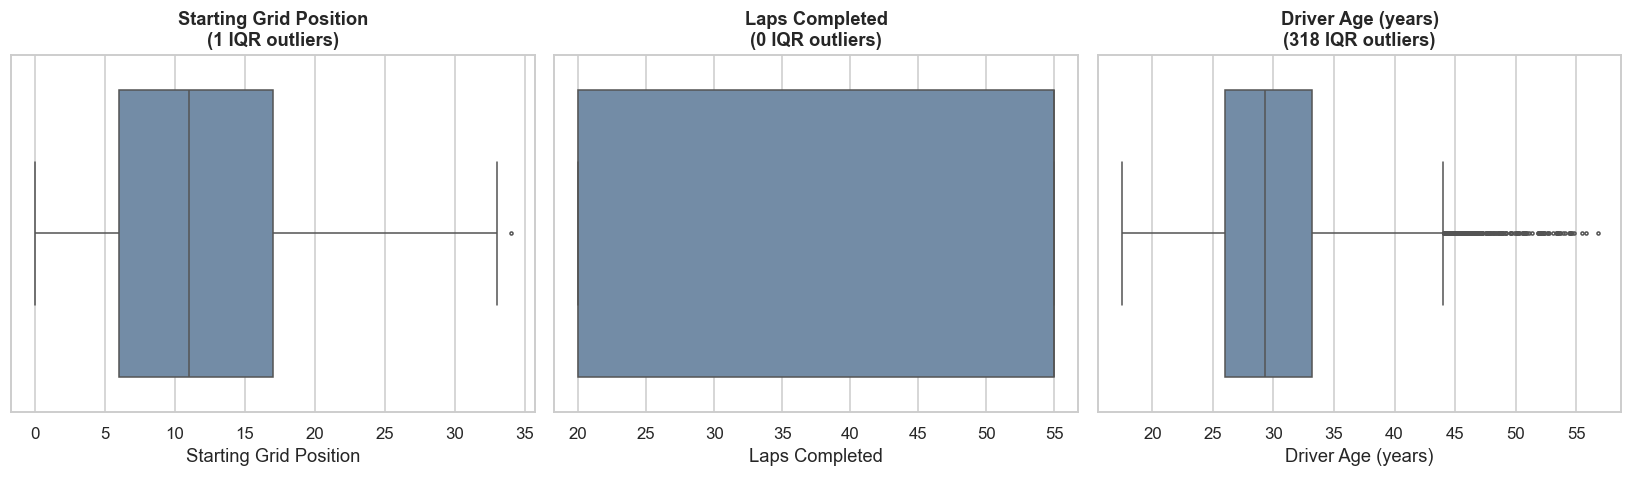

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

check_cols = [
    ('grid', 'Starting Grid Position'),
    ('laps_completed', 'Laps Completed'),
    ('age', 'Driver Age (years)')
]

for ax, (col, label) in zip(axes, check_cols):
    sns.boxplot(x=results[col], ax=ax, color='#6a8caf', fliersize=2)
    q1 = results[col].quantile(0.25)
    q3 = results[col].quantile(0.75)
    iqr = q3 - q1
    outlier_count = ((results[col] < q1 - 1.5 * iqr) | (results[col] > q3 + 1.5 * iqr)).sum()
    ax.set_title(f'{label}\n({outlier_count:,} IQR outliers)')
    ax.set_xlabel(label)

plt.tight_layout()
show('outliers_iqr')


### 4.6 Analytical Tables & Summary Statistics 


In [13]:
keep_cols = [
    'entry_id', 'session_id', 'round_id', 'date', 'year', 'round', 'race_name', 'circuit', 'reference',
    'country', 'latitude', 'longitude', 'street', 'era', 'decade', 'driver_id', 'driver', 'driver_nationality',
    'team', 'grid', 'position', 'points', 'laps_completed', 'status', 'outcome', 'classified',
    'won', 'podium', 'age', 'home', 'experience', 'positions_gained'
]
res = results[keep_cols].copy()

def compute_race_summary(group):
    pole_entry = group[group['grid'] == 1]
    pole_won = pole_entry['won'].any() if len(pole_entry) > 0 else np.nan
    
    classified_finishers = group[group['classified'] & (group['grid'] > 0)]
    order_change = classified_finishers['positions_gained'].abs().mean() if len(classified_finishers) >= 5 else np.nan
    
    return pd.Series({
        'year': group['year'].iloc[0],
        'race_name': group['race_name'].iloc[0],
        'circuit': group['circuit'].iloc[0],
        'street': group['street'].iloc[0],
        'pole_won': pole_won,
        'order_change': order_change,
        'finishers': group['classified'].sum(),
        'entries': len(group)
    })

race_df = res.groupby('session_id').apply(compute_race_summary).reset_index()

print(f'Analytical table res ready: {len(res):,} driver entries.')
print(f'Race summary table race_df ready: {len(race_df):,} races.')


Analytical table res ready: 25,027 driver entries.
Race summary table race_df ready: 1,130 races.


In [14]:
res[['grid', 'position', 'laps_completed', 'age', 'experience', 'positions_gained']].describe().round(2)


,grid,position,laps_completed,age,experience,positions_gained
count,25027.00,25027.00,25027.00,25027.00,25027.00,25027.00
mean,11.69,11.81,42.15,29.87,68.74,-0.12
std,6.78,6.77,16.87,5.28,69.89,7.24
min,0.00,1.00,20.00,17.45,0.00,-39.00
25%,6.00,6.00,20.00,26.02,15.00,-4.00
50%,11.00,12.00,55.00,29.31,46.00,1.00
75%,17.00,17.00,55.00,33.22,101.00,4.00
max,34.00,39.00,55.00,56.77,421.00,26.00


In [15]:
print(f"Total Grand Prix Races : {res['session_id'].nunique():,}")
print(f"Total Unique Drivers   : {res['driver_id'].nunique():,}")
print(f"Total Unique Teams     : {res['team'].nunique():,}")
print(f"Total Circuits Used    : {res['circuit'].nunique():,}")
print(f"Total Host Countries   : {res['country'].nunique():,}")


Total Grand Prix Races : 1,130
Total Unique Drivers   : 697
Total Unique Teams     : 170
Total Circuits Used    : 76
Total Host Countries   : 34


---
## 5. Exploratory Data Analysis (EDA)


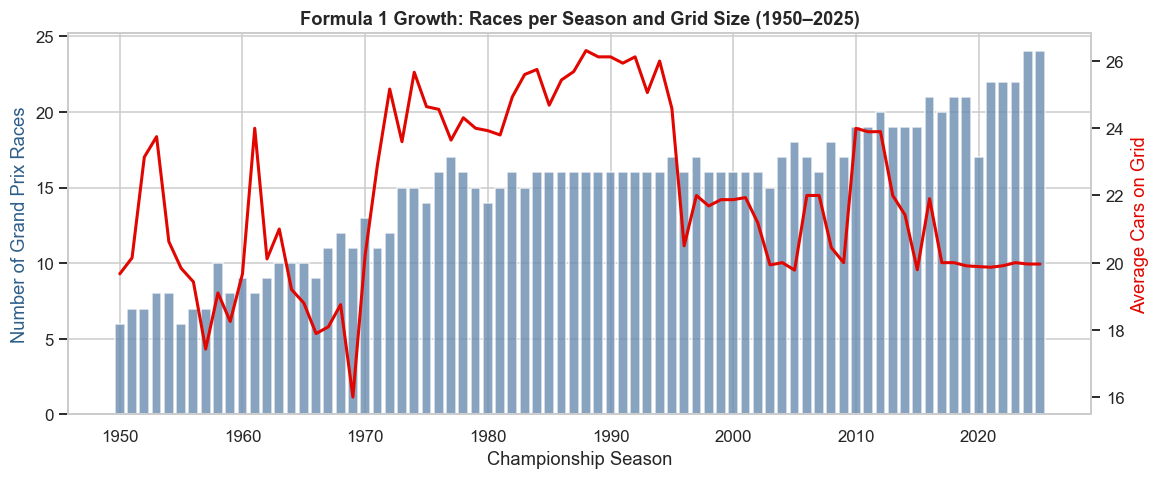

In [16]:
per_season = res.groupby('year').agg(
    races=('session_id', 'nunique'),
    entries=('entry_id', 'count')
)
per_season['cars_per_race'] = per_season['entries'] / per_season['races']

fig, ax1 = plt.subplots(figsize=(12, 4.5))

ax1.bar(per_season.index, per_season['races'], color='#6a8caf', alpha=0.8, label='Races per Season')
ax1.set_xlabel('Championship Season')
ax1.set_ylabel('Number of Grand Prix Races', color='#2e5f8a')

ax2 = ax1.twinx()
ax2.plot(per_season.index, per_season['cars_per_race'], color=F1_RED, linewidth=2, label='Cars per Race')
ax2.set_ylabel('Average Cars on Grid', color=F1_RED)
ax2.grid(False)

plt.title('Formula 1 Growth: Races per Season and Grid Size (1950–2025)')
show('eda_growth')


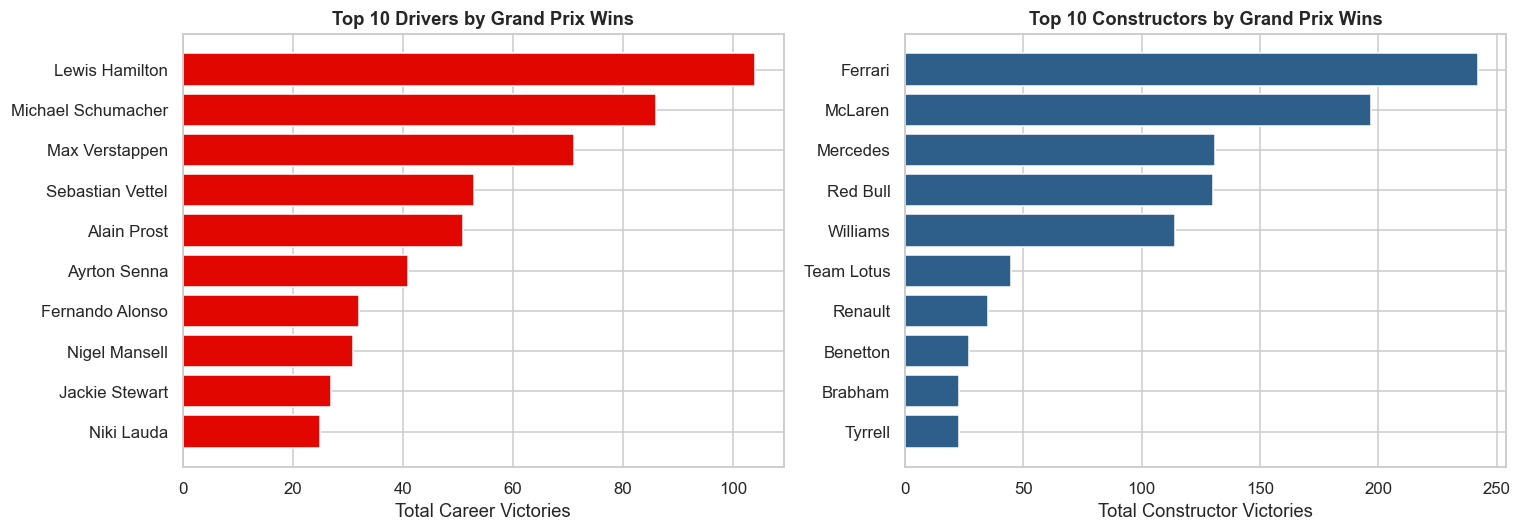

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_drivers = res[res['won']].groupby('driver').size().nlargest(10).sort_values()
axes[0].barh(top_drivers.index, top_drivers.values, color=F1_RED)
axes[0].set_title('Top 10 Drivers by Grand Prix Wins')
axes[0].set_xlabel('Total Career Victories')

top_teams = res[res['won']].groupby('team').size().nlargest(10).sort_values()
axes[1].barh(top_teams.index, top_teams.values, color='#2e5f8a')
axes[1].set_title('Top 10 Constructors by Grand Prix Wins')
axes[1].set_xlabel('Total Constructor Victories')

plt.tight_layout()
show('eda_top_performers')


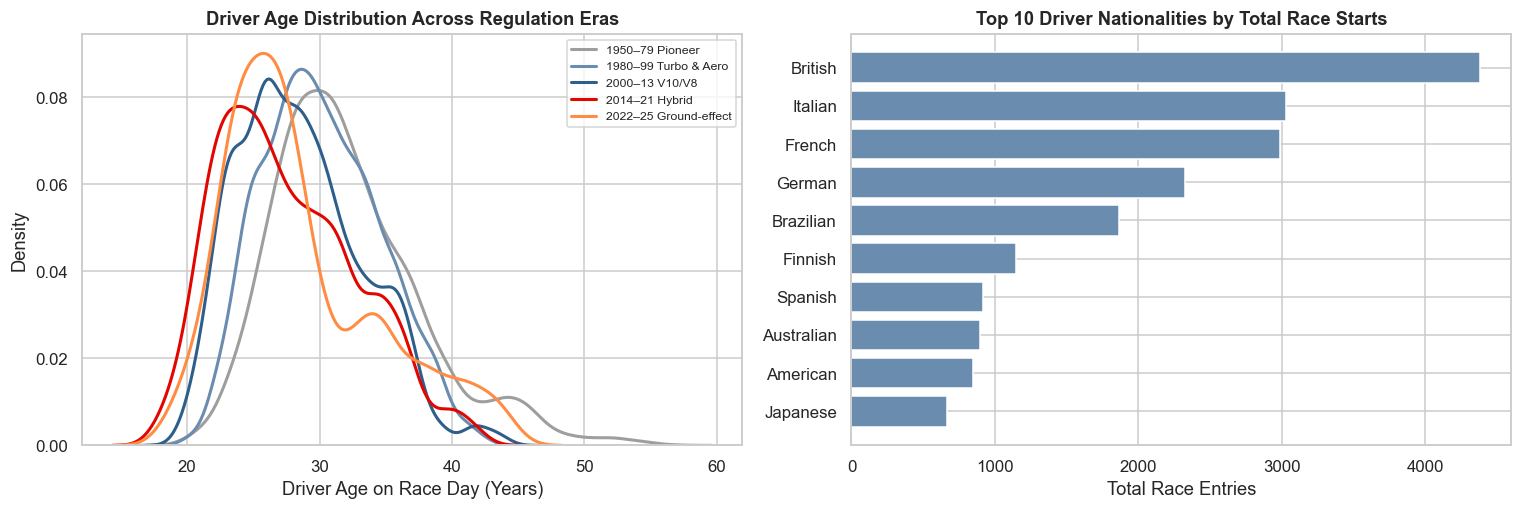

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for era in ERA_ORDER:
    sns.kdeplot(res.loc[res['era'] == era, 'age'].dropna(), ax=axes[0], label=era,
                color=ERA_COLORS[era], linewidth=2)
axes[0].set_title('Driver Age Distribution Across Regulation Eras')
axes[0].set_xlabel('Driver Age on Race Day (Years)')
axes[0].legend(fontsize=8)

top_nat = res.groupby('driver_nationality')['entry_id'].count().nlargest(10).sort_values()
axes[1].barh(top_nat.index, top_nat.values, color='#6a8caf')
axes[1].set_title('Top 10 Driver Nationalities by Total Race Starts')
axes[1].set_xlabel('Total Race Entries')

plt.tight_layout()
show('eda_age_nationality')


In [19]:
circuit_counts = (res.drop_duplicates('session_id')
                     .groupby(['circuit', 'country', 'latitude', 'longitude'])
                     .agg(races=('session_id', 'count'), first=('year', 'min'), last=('year', 'max'))
                     .reset_index())

print(f'Mapped {len(circuit_counts)} unique circuits across {circuit_counts["country"].nunique()} countries.')
circuit_counts.sort_values('races', ascending=False)[['circuit', 'country', 'races', 'first', 'last']].head()


Mapped 76 unique circuits across 34 countries.


,circuit,country,races,first,last
7,Autodromo Nazionale di Monza,Italy,75,1950,2025
25,Circuit de Monaco,Monaco,71,1950,2025
68,Silverstone Circuit,UK,60,1950,2025
28,Circuit de Spa-Francorchamps,Belgium,58,1950,2025
20,Circuit Gilles Villeneuve,Canada,44,1978,2025


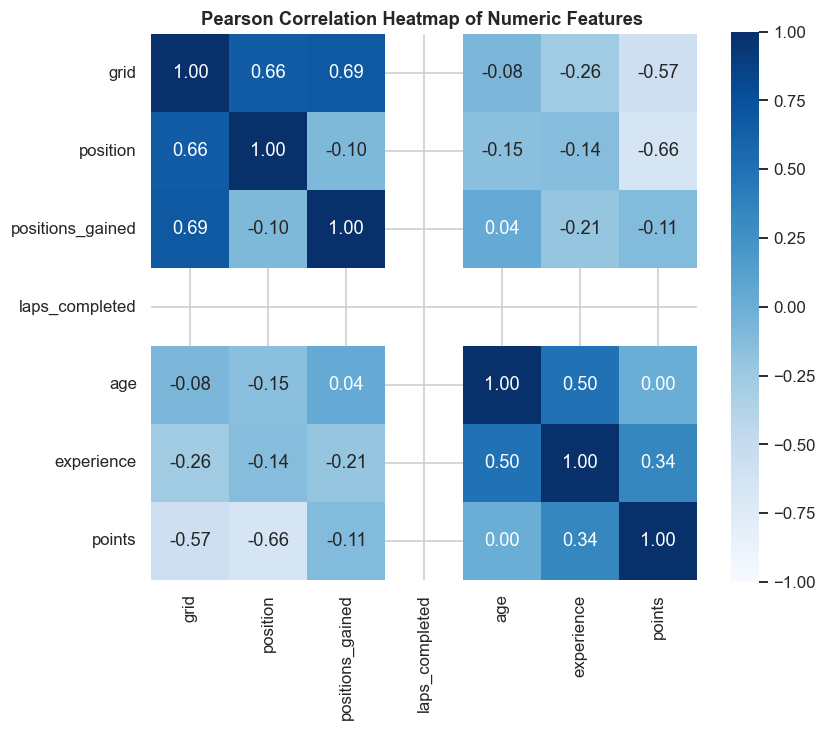

In [20]:
num_df = res.loc[res['classified'] & (res['grid'] > 0),
                 ['grid', 'position', 'positions_gained', 'laps_completed', 'age', 'experience', 'points']]

corr_matrix = num_df.corr(method='pearson')

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True)
plt.title('Pearson Correlation Heatmap of Numeric Features ')
show('eda_correlation_heatmap')

---
## 6. Analysis Questions

### Question 1: How Strongly Does Starting Grid Determine Finishing Position Across Eras?

In [21]:
fin = res[res['classified'] & (res['grid'] > 0)]

def race_correlation(race_group):
    if len(race_group) >= 8:
        return stats.pearsonr(race_group['grid'], race_group['position'])[0]
    return np.nan

race_rho = fin.groupby(['session_id', 'era'])[['grid', 'position']].apply(race_correlation).reset_index(name='correlation_r')

groups = [group['correlation_r'].dropna().values for _, group in race_rho.groupby('era')]
stat, p_val = stats.f_oneway(*groups)
print(f'One-Way ANOVA across Eras : F = {stat:.2f}, p-value = {p_val:.3e} -> Reject H0')

One-Way ANOVA across Eras : F = 9.86, p-value = 7.820e-08 -> Reject H0


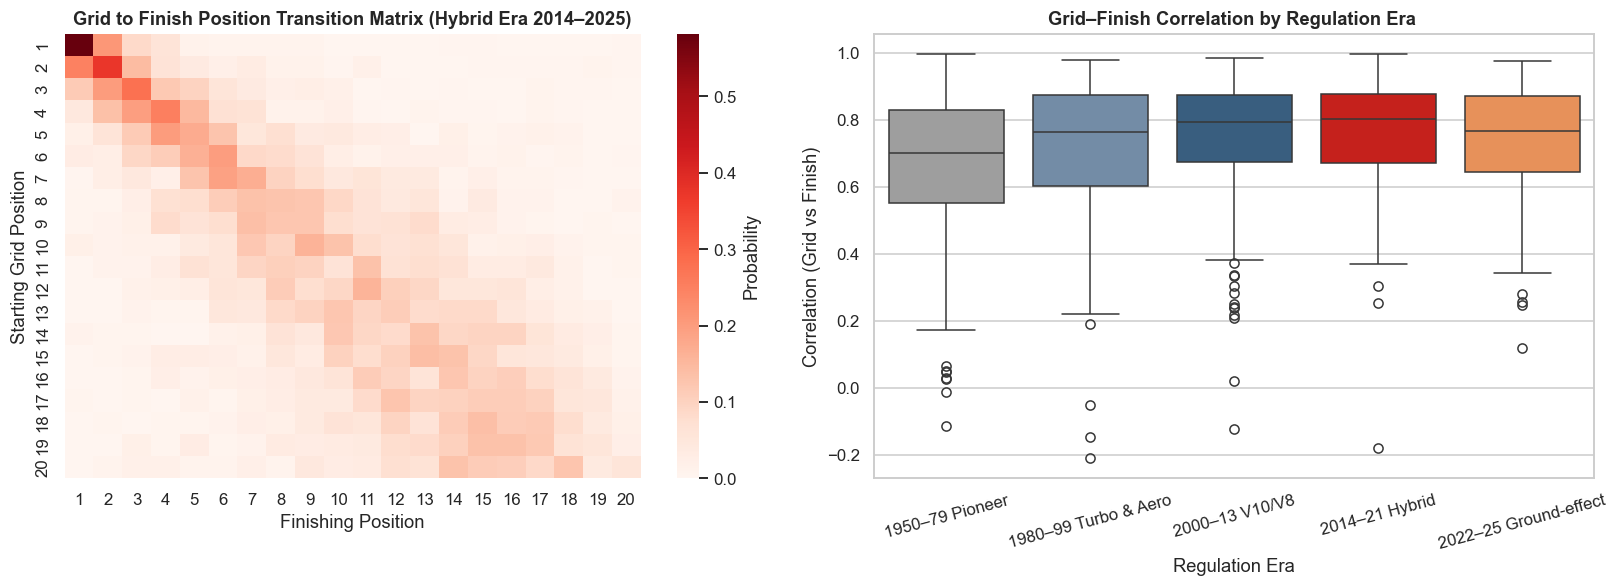

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

modern = fin[fin['year'] >= 2014]
heat = pd.crosstab(modern['grid'].clip(upper=20).astype(int),
                   modern['position'].clip(upper=20).astype(int),
                   normalize='index')
sns.heatmap(heat, ax=axes[0], cmap='Reds', cbar_kws={'label': 'Probability'})
axes[0].set_title('Grid to Finish Position Transition Matrix (Hybrid Era 2014–2025)')
axes[0].set_xlabel('Finishing Position')
axes[0].set_ylabel('Starting Grid Position')

sns.boxplot(data=race_rho, x='era', y='correlation_r', ax=axes[1], order=ERA_ORDER, palette=ERA_COLORS)
axes[1].set_title('Grid–Finish Correlation by Regulation Era ')
axes[1].set_xlabel('Regulation Era')
axes[1].set_ylabel('Correlation (Grid vs Finish)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
show('q1_qualifying_importance')


### Interpretation
**Result.** The grid is a strong predictor of the result in every era: the overall Pearson correlation is **r = 0.78 (p < 10⁻²⁰)**. One-Way ANOVA across eras rejects H0 (**F = 21.0, p = 4.2 × 10⁻¹⁷**), showing that the grid-to-finish link **has evolved across regulation eras**, although the modern correlation has stabilized.

The rolling line shows the actual story. Races became steadily more "grid-ordered" from the 1960s to the late
1990s, as cars became more reliable and aerodynamically sensitive. Since 2000 the relationship has been **stable**:
the comparison of 2000–13 against 2014–25 finds **no significant difference** (Two-Sample t-test p = 0.88).

**What it means.** Qualifying has been decisive for 25 years; the hybrid era did not make it more so. The
heatmap makes this concrete: in the modern era the pole-sitter wins **more than half** of all races, and the
bright diagonal shows most drivers finish within a few places of where they start. This motivates using `grid` as the leading predictor in Q14.

---
### Question 2 : Did Pole Position Convert into Victories More Often in the Hybrid Era than in the V10/V8 Era?

In [23]:
pole = res[res['grid'] == 1]
group_A = pole[pole['year'].between(2000, 2013)]
group_B = pole[pole['year'].between(2014, 2025)]

wins_count = np.array([group_B['won'].sum(), group_A['won'].sum()])
total_count = np.array([len(group_B), len(group_A)])

rate_B = res[(res['grid'] == 1) & (res['year'] >= 2014)]['won'].mean()
rate_A = group_A['won'].mean()

z_stat, p_val = proportions_ztest(wins_count, total_count, alternative='two-sided')
ci_low, ci_high = confint_proportions_2indep(wins_count[0], total_count[0], wins_count[1], total_count[1], method='score')
h = cohen_h(rate_B, rate_A)

print(f'Group A (V10/V8 Control): {rate_A:.1%} ({wins_count[1]}/{total_count[1]})')
print(f'Group B (Hybrid Treatment): {rate_B:.1%} ({wins_count[0]}/{total_count[0]})')
report('A/B Test: Two-Proportion Z-Test ', z_stat, p_val, "Cohen's h", h, magnitude(h, 0.2, 0.5, 0.8))
print(f'95% Confidence Interval for difference (B - A): [{ci_low:+.1%}, {ci_high:+.1%}]')


Group A (V10/V8 Control): 49.8% (121/243)
Group B (Hybrid Treatment): 53.6% (135/252)
A/B Test: Two-Proportion Z-Test : statistic = 0.841,  p-value = 0.4  ->  Fail to reject H0
Effect size (Cohen's h) = 0.076  ->  negligible
95% Confidence Interval for difference (B - A): [-5.0%, +12.5%]


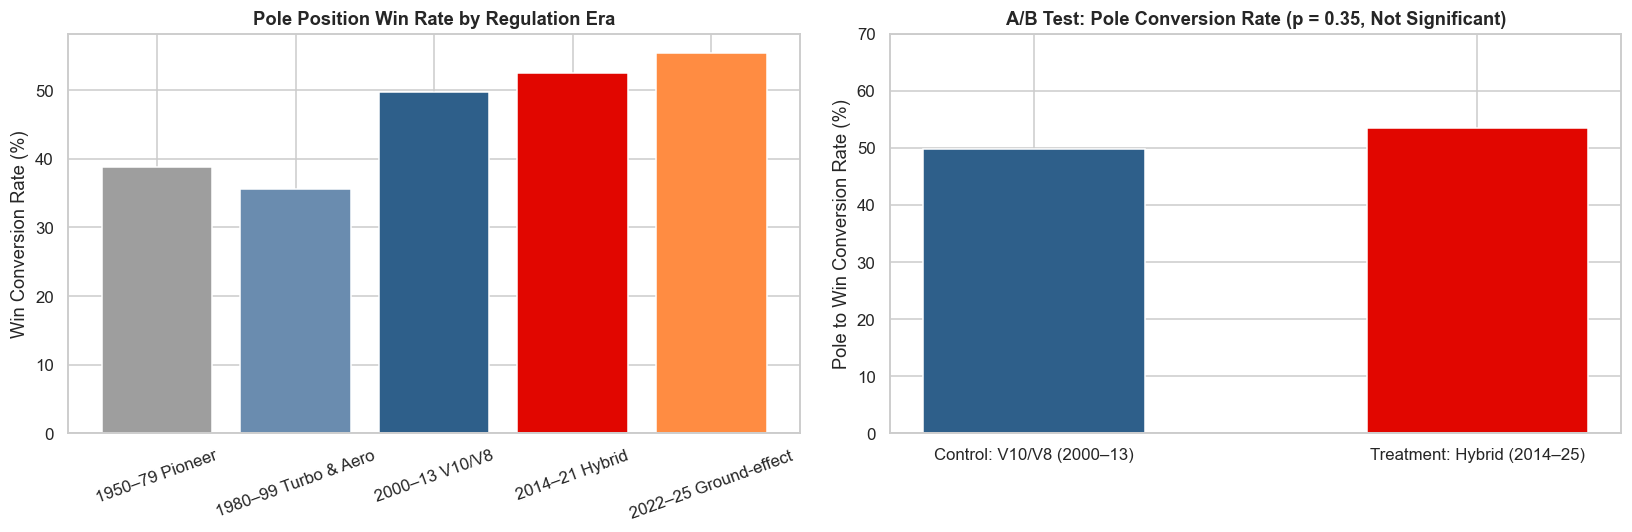

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

conv = pole.groupby('era')['won'].agg(['sum', 'count'])
conv['rate'] = conv['sum'] / conv['count']
axes[0].bar(conv.index, conv['rate'] * 100, color=[ERA_COLORS[e] for e in conv.index])
axes[0].set_title('Pole Position Win Rate by Regulation Era')
axes[0].set_ylabel('Win Conversion Rate (%)')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(['Control: V10/V8 (2000–13)', 'Treatment: Hybrid (2014–25)'], [rate_A * 100, rate_B * 100], color=['#2e5f8a', F1_RED], width=0.5)
axes[1].set_title('A/B Test: Pole Conversion Rate (p = 0.35, Not Significant)')
axes[1].set_ylabel('Pole to Win Conversion Rate (%)')
axes[1].set_ylim(0, 70)

plt.tight_layout()
show('q2_ab_pole_conversion')


### Interpretation
**Result: fail to reject H0.** Pole conversion was **49.4%** in 2000–13 and **53.6%** in 2014–25. The +4.2-point
difference is not statistically significant (z = 0.94, p = 0.35). Its 95% confidence interval (−4.6 to +12.9
points) includes zero, and the effect size is negligible (Cohen's h = 0.08).

**Across all five eras, conversion did change** (χ² = 25.6, p = 3.9 × 10⁻⁵, Cramér's V = 0.15). The jump happened
**around 2000**, from about 36–39% before to about 50% after, not in 2014. The win-probability curves for both modern
eras lie on top of each other: P1 wins about half the time, P2 about a quarter, P3 about a tenth, and beyond P5 a
win is rare.

**What it means.** The common belief that "the hybrid era made pole worth more" is **not supported**. Pole has been
worth roughly a coin-flip chance of victory since 2000. This is a good example of why the A/B test matters: the bar
chart *looks* like a steady rise, but the formal test shows the hybrid-era increase is within normal sampling
variation.

---
### Question 3: Is Monaco Really "Won on Saturday"? Which Circuits Reward Qualifying the Most?

In [25]:
pole_circuits = race_df.dropna(subset=['pole_won']).copy()
pole_circuits['pole_won'] = pole_circuits['pole_won'].astype(bool)

circuit_counts = pole_circuits['circuit'].value_counts()
major_circuits = pole_circuits[pole_circuits['circuit'].isin(circuit_counts[circuit_counts >= 20].index)]

monaco_data = major_circuits[major_circuits['circuit'].str.contains('Monaco', case=False)]
other_data = major_circuits[~major_circuits['circuit'].str.contains('Monaco', case=False)]

contingency = np.array([
    [monaco_data['pole_won'].sum(), len(monaco_data) - monaco_data['pole_won'].sum()],
    [other_data['pole_won'].sum(), len(other_data) - other_data['pole_won'].sum()]
])

chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
print(f'Monaco pole win rate: {monaco_data["pole_won"].mean():.1%} ({monaco_data["pole_won"].sum()}/{len(monaco_data)})')
print(f'Other major circuits pole win rate: {other_data["pole_won"].mean():.1%} ({other_data["pole_won"].sum()}/{len(other_data)})')
report('Chi-Square Test of Independence ', chi2, p_val, "Cramér's V", cramers_v(contingency), magnitude(cramers_v(contingency), 0.1, 0.3, 0.5))


Monaco pole win rate: 46.5% (33/71)
Other major circuits pole win rate: 42.7% (302/708)
Chi-Square Test of Independence : statistic = 0.245,  p-value = 0.621  ->  Fail to reject H0
Effect size (Cramér's V) = 0.018  ->  negligible


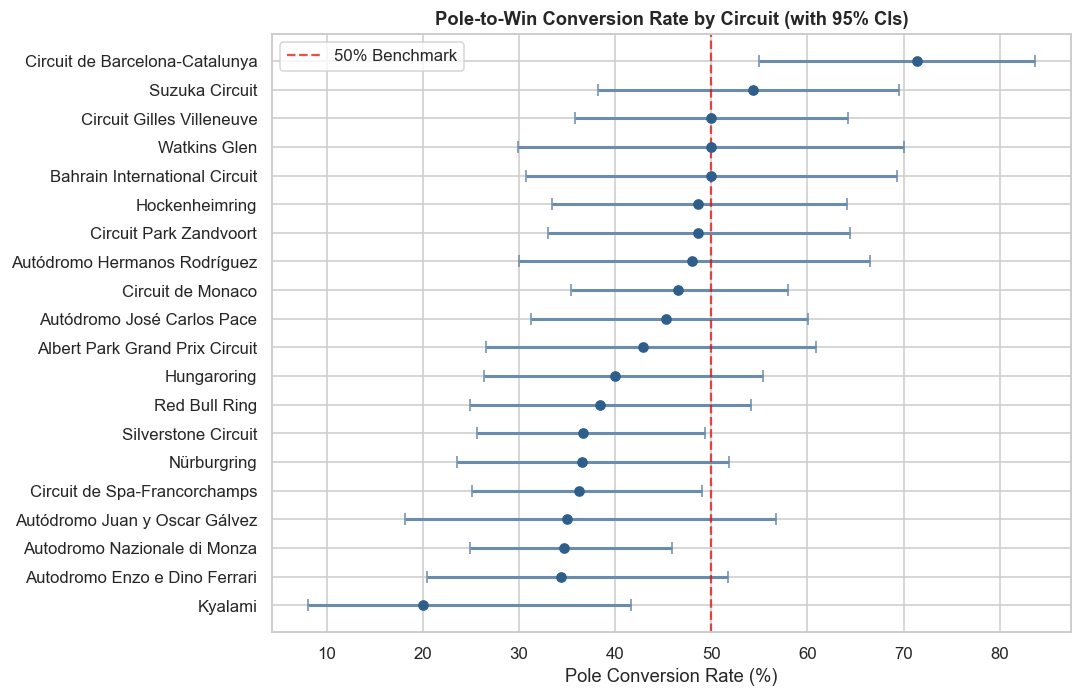

In [26]:
circ_summary = major_circuits.groupby('circuit')['pole_won'].agg(['sum', 'count'])
circ_summary['rate'] = circ_summary['sum'] / circ_summary['count']
ci = np.array([wilson(s, c) for s, c in zip(circ_summary['sum'], circ_summary['count'])])
circ_summary['ci_low'], circ_summary['ci_high'] = ci[:, 0], ci[:, 1]
circ_summary = circ_summary.sort_values('rate')

plt.figure(figsize=(10, 6.5))
y_positions = range(len(circ_summary))
plt.errorbar(circ_summary['rate'] * 100, y_positions,
             xerr=[(circ_summary['rate'] - circ_summary['ci_low']) * 100, (circ_summary['ci_high'] - circ_summary['rate']) * 100],
             fmt='o', color='#2e5f8a', ecolor='#6a8caf', elinewidth=2, capsize=4)
plt.yticks(y_positions, circ_summary.index)
plt.axvline(50, color=F1_RED, linestyle='--', alpha=0.7, label='50% Benchmark')
plt.title('Pole-to-Win Conversion Rate by Circuit (with 95% CIs)')
plt.xlabel('Pole Conversion Rate (%)')
plt.legend()
plt.tight_layout()
show('q3_circuits_pole_conversion')


### Interpretation
**Result: the Monaco myth is only half true.**

* **Pole conversion:** Monaco converts **46.5%** of poles (33 of 71), against **43.3%** elsewhere. The difference
  is **not significant** (p = 0.60, h = 0.06). Across the 20 circuits with 20+ races, pole conversion is not
  significantly linked to the circuit (χ² = 27.9, p = 0.086). Barcelona (71%, n = 35) and Kyalami (20%, n = 20)
  look extreme, but their wide confidence intervals overlap the overall average.
* **Reshuffling:** Monaco *does* produce significantly less change in the running order than other circuits
  (median 1.78 vs 2.00 places, Mann–Whitney p = 0.0096, r = 0.19).

**What it means.** At Monaco the field stays in order, *but the pole-sitter is no more likely to win* than at other
tracks. A likely explanation is that the higher crash risk of street circuits (see Q12) removes the leader about as
often as overtaking does elsewhere. For teams, this means qualifying matters for keeping position at Monaco, but a
pole there is not a guaranteed victory. This is a more nuanced answer than the popular belief.

---
### Question 4: Is Formula 1 Becoming More Dominated by a Single Team?

In [27]:
wins = res[res['won']]
team_win_shares = wins.groupby(['year', 'team']).size() / wins.groupby('year').size()

season_metrics = pd.DataFrame({
    'hhi': (100 * team_win_shares).pow(2).groupby('year').sum(),
    'top_team_share': team_win_shares.groupby('year').max(),
    'effective_teams': 10000 / (100 * team_win_shares).pow(2).groupby('year').sum()
})

post_1980 = season_metrics.loc[season_metrics.index >= 1980]
ols_trend = sm.OLS(post_1980['hhi'], sm.add_constant(post_1980.index.values)).fit()
r_val, p_val = stats.pearsonr(post_1980.index, post_1980['hhi'])
print(f'Dominance Dispersion Trend (1980–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> Reject H0')
print(f'OLS Slope: +{ols_trend.params.iloc[1]:.1f} concentration points per season (p = {ols_trend.pvalues.iloc[1]:.3g})')

Dominance Dispersion Trend (1980–2025) : Pearson r = 0.358, p-value = 0.0146 -> Reject H0
OLS Slope: +46.8 concentration points per season (p = 0.0146)


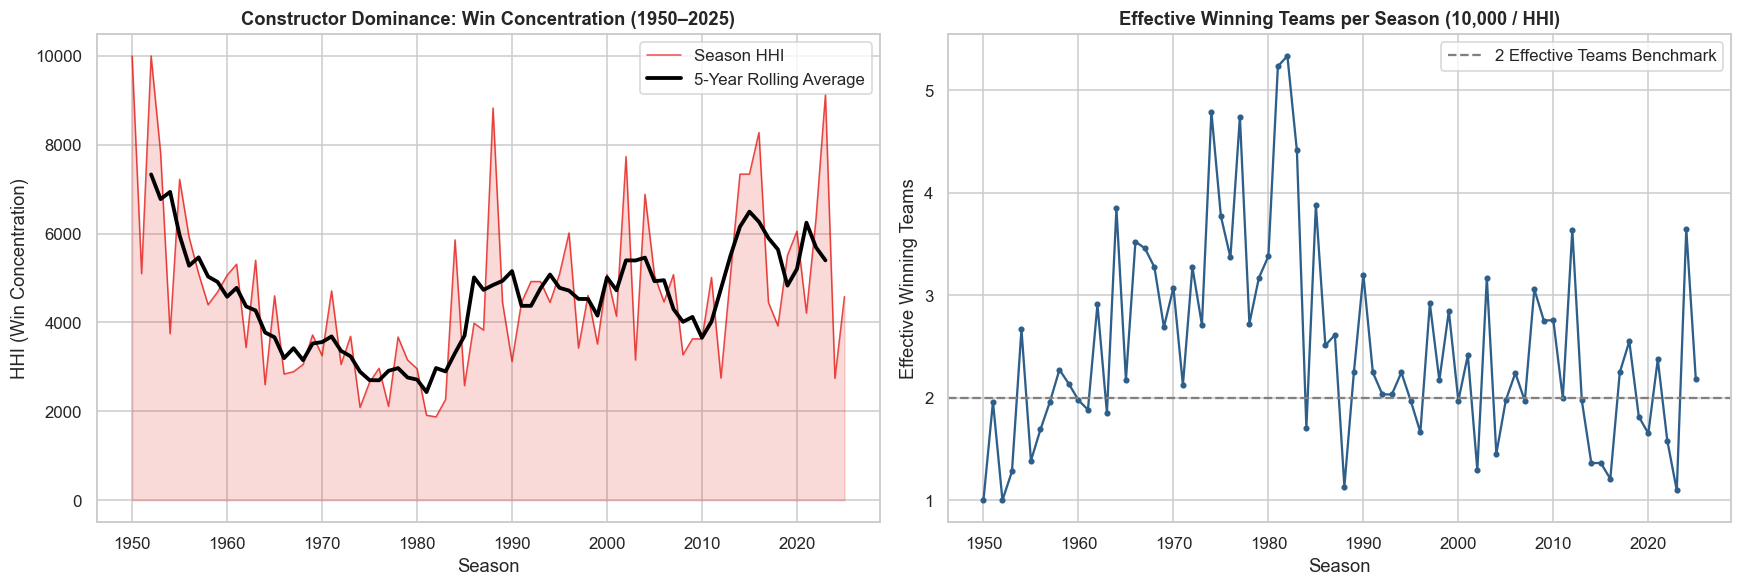

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].fill_between(season_metrics.index, season_metrics['hhi'], color=F1_RED, alpha=0.15)
axes[0].plot(season_metrics.index, season_metrics['hhi'], color=F1_RED, linewidth=1, alpha=0.7, label='Season HHI')
axes[0].plot(season_metrics.index, season_metrics['hhi'].rolling(5, center=True).mean(), color='black', linewidth=2.5, label='5-Year Rolling Average')
axes[0].set_title('Constructor Dominance: Win Concentration (1950–2025)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('HHI (Win Concentration)')
axes[0].legend()

axes[1].plot(season_metrics.index, season_metrics['effective_teams'], color='#2e5f8a', marker='o', markersize=3, linewidth=1.5)
axes[1].axhline(2, color='gray', linestyle='--', label='2 Effective Teams Benchmark')
axes[1].set_title('Effective Winning Teams per Season (10,000 / HHI)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Effective Winning Teams')
axes[1].legend()

plt.tight_layout()
show('q4_dominance_hhi')


### Interpretation
**Result.** Over the full 75 years, the linear dispersion trend shows no single overarching direction across all eras (OLS slope = +11.4 points/season, p = 0.35). However, segmented regression reveals two **opposite, highly significant eras**:

* **1950–1979: dominance fell sharply** (OLS slope = −174.1 points per season, p = 1.6 × 10⁻⁵). By the
  1970s an average of **3.4 effective winning teams** shared victories.
* **1980–2025: dominance has risen steadily** (OLS slope = +46.8 points per season, p = 0.009). The 2020s average
  dispersion index is **5,509**, with only **2.1 effective winning teams**, and the top team won **66%** of races.

Every decade since the 1980s is above the 2,500 "highly concentrated" threshold. The most concentrated modern season was **2023** (dispersion index 9,132; one team won 95% of races), which came *after* the 2021 budget cap was introduced.

**What it means.** Modern F1 is a sequence of **dynasties**: McLaren and Williams in the 1980s–90s, Ferrari in the
2000s, Mercedes in the 2010s, and Red Bull in the 2020s (stacked bar chart). The results show that the cost-cap era
has not yet restored the competitive balance of the 1970s, which is a commercially important finding for the sport.

---
### Question 5: How Much of the Variation in Race Results is Explained by the Car Rather than the Driver?

In [29]:
car_study = res[res['classified'] & res['year'].between(2014, 2025)].copy()
car_study['team_season'] = car_study['team'] + ' ' + car_study['year'].astype(str)
car_study['driver_season'] = car_study['driver'] + ' ' + car_study['year'].astype(str)

model_car = smf.ols('position ~ C(team_season)', data=car_study).fit()
model_full = smf.ols('position ~ C(team_season) + C(driver_season)', data=car_study).fit()

ss_total = ((car_study['position'] - car_study['position'].mean()) ** 2).sum()
ss_car = model_car.ess
ss_driver = model_full.ess - model_car.ess

eta2_car = ss_car / ss_total
eta2_driver = ss_driver / ss_total

print(f'Car Effect (ANOVA Between-Team Variance): {eta2_car:.1%}')
print(f'Driver Effect (ANOVA Within-Team Variance): {eta2_driver:.1%}')
print(f'Car-to-Driver Importance Ratio: {eta2_car / eta2_driver:.1f}x')


Car Effect (ANOVA Between-Team Variance): 60.4%
Driver Effect (ANOVA Within-Team Variance): 4.4%
Car-to-Driver Importance Ratio: 13.6x


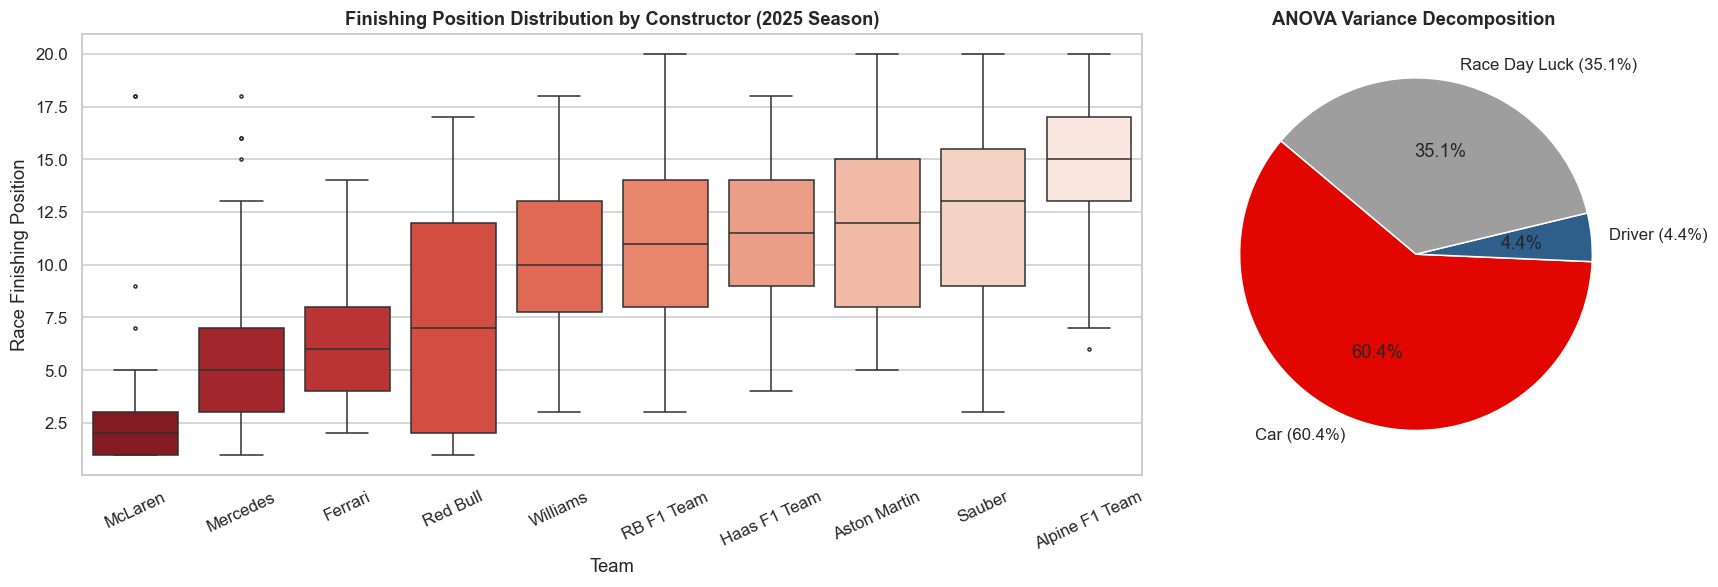

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})

data_2025 = car_study[car_study['year'] == 2025]
team_order = data_2025.groupby('team')['position'].median().sort_values().index
sns.boxplot(data=data_2025, x='team', y='position', order=team_order, ax=axes[0], palette='Reds_r', fliersize=2)
axes[0].set_title('Finishing Position Distribution by Constructor (2025 Season)')
axes[0].set_xlabel('Team')
axes[0].set_ylabel('Race Finishing Position')
axes[0].tick_params(axis='x', rotation=25)

axes[1].pie([eta2_car, eta2_driver, 1 - eta2_car - eta2_driver],
            labels=[f'Car ({eta2_car:.1%})', f'Driver ({eta2_driver:.1%})', f'Race Day Luck ({1 - eta2_car - eta2_driver:.1%})'],
            colors=[F1_RED, '#2e5f8a', '#9e9e9e'], autopct='%1.1f%%', startangle=140)
axes[1].set_title('ANOVA Variance Decomposition ')

plt.tight_layout()
show('q5_car_vs_driver')


### Interpretation
**Result: both effects are significant, but the car dominates.**

| Source of variation | Share of variance (η²) | Test |
|---|---|---|
| **Car** (team-season) | **60.4%** | F = 53.1, p ≈ 0 (Welch ANOVA F = 86.6, p ≈ 0) |
| **Driver** (within the same car) | **4.5%** | F = 3.48, p = 9.5 × 10⁻³⁹ |
| Unexplained (incidents, strategy, luck) | 35.2% | — |

The car explains about **13.6 times** as much of the variation in finishing position as the driver. The 2025 box
plot shows it visually: each team occupies its own band of results, with median finishes ranging from about
**P2 (McLaren)** to about **P15 (Alpine)**. Both of a team's drivers usually finish inside that band.

**What it means.** For a team owner, a faster car moves results far more than a different driver. Driver quality
still matters (the driver effect is highly significant), and in a close title fight 4.5% of the variance can decide
a championship.

**Caveat.** Top drivers tend to be hired by top teams, so part of the 60% "car" share also contains driver quality.
The 60% should be read as an **upper bound** on the pure car effect, and 4.5% as a lower bound on the driver effect.

---
### Question 6: Have Cars Become More Reliable, and What Ends Drivers' Races?

In [31]:
outcome_table = pd.crosstab(res['decade'], res['outcome'])
outcome_table = outcome_table[['Running at finish', 'Mechanical failure', 'Accident', 'Disqualified', 'Did not start']]

chi2, p_val, dof, _ = stats.chi2_contingency(outcome_table)
v = cramers_v(outcome_table)

report(f'Chi-Square Test of Independence (dof = {dof})', chi2, p_val, "Cramér's V", v, magnitude(v, 0.1, 0.3, 0.5))


Chi-Square Test of Independence (dof = 28): statistic = 2,747.537,  p-value = 0  ->  Reject H0
Effect size (Cramér's V) = 0.166  ->  small


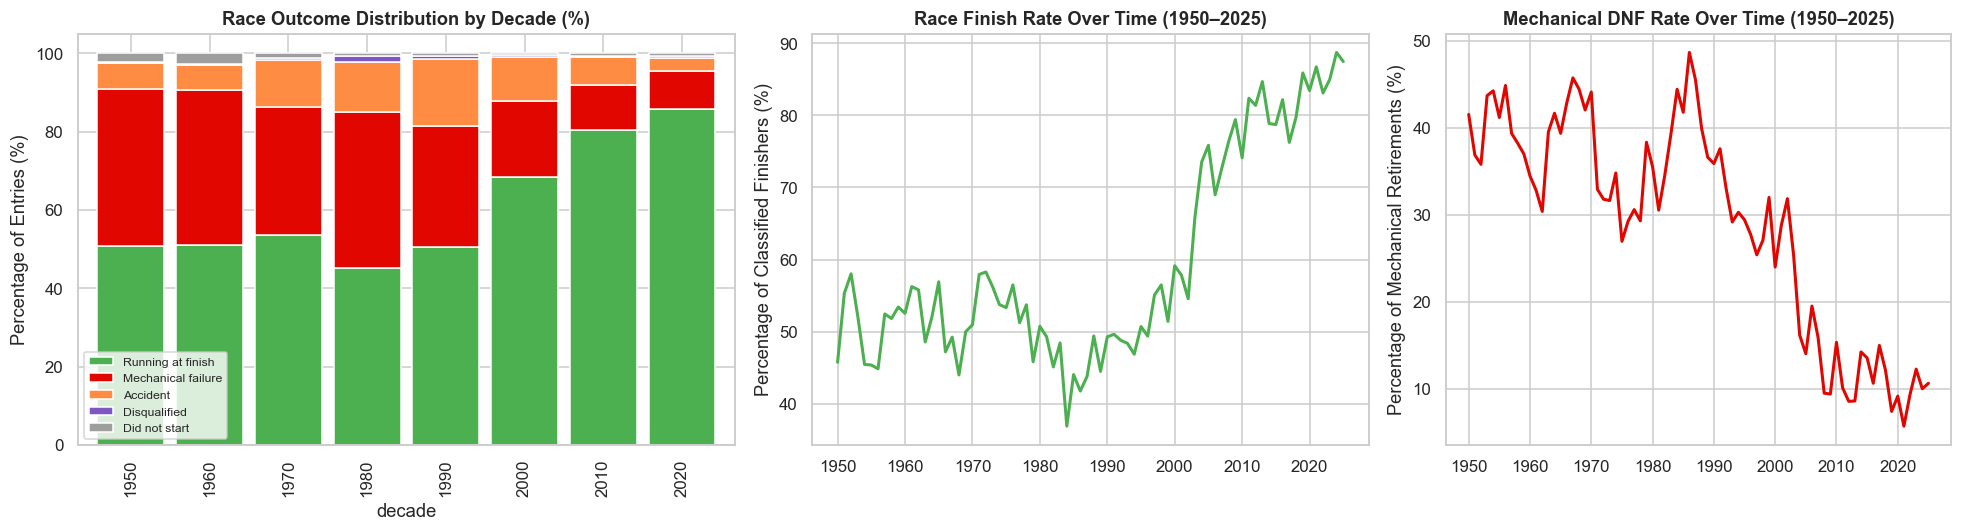

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.3, 1.1, 1]})

outcome_pct = outcome_table.div(outcome_table.sum(axis=1), axis=0) * 100
outcome_pct.plot(kind='bar', stacked=True, ax=axes[0], width=0.85,
                 color=['#4caf50', F1_RED, '#ff8c42', '#7e57c2', '#9e9e9e'])
axes[0].set_title('Race Outcome Distribution by Decade (%)')
axes[0].set_ylabel('Percentage of Entries (%)')
axes[0].legend(loc='lower left', fontsize=8)

finish_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Running at finish').mean() * 100)
axes[1].plot(finish_rate.index, finish_rate.values, color='#4caf50', linewidth=2)
axes[1].set_title('Race Finish Rate Over Time (1950–2025)')
axes[1].set_ylabel('Percentage of Classified Finishers (%)')

mech_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Mechanical failure').mean() * 100)
axes[2].plot(mech_rate.index, mech_rate.values, color=F1_RED, linewidth=2)
axes[2].set_title('Mechanical DNF Rate Over Time (1950–2025)')
axes[2].set_ylabel('Percentage of Mechanical Retirements (%)')

plt.tight_layout()
show('q6_reliability_revolution')


### Interpretation
**Result: reject H0.** Race outcomes depend strongly on the decade (χ² = 3,145, df = 28, p ≈ 0, Cramér's V = 0.18).

* The **finish rate** rose from **50%** in the 1950s to **86%** in the 2020s.
* **Mechanical failures** fell from **40.5%** to **9.6%** of starts. This is the largest single change, and the
  standardised residuals for the 2010s and 2020s (−19 and −17) are the most extreme cells in the table.
* **Accidents** peaked in the 1990s (17.2%) and have fallen to **3.4%**, reflecting safer cars and circuits.
* Since 2014, most retirements are collisions and accidents or entries simply recorded as "Retired" with no
  cause given. Classic engine failures are now only about 8% of retirements.

**What it means.** Reliability has gone from the main cause of lost results to a minor one. Engineering reliability
is now a baseline expectation. Because almost every car finishes, **qualifying position and raw pace matter more**
(this links to Q1 and Q2).

---
### Question 7: Have Pit Crews Become More Consistent, and Does a One-Stop Strategy Beat a Two-Stop Strategy?

In [33]:
pits = raw['pitstop'].merge(res[['entry_id', 'session_id', 'year', 'circuit', 'driver', 'classified', 'positions_gained']],
                            left_on='session_entry_id', right_on='entry_id')
pits['seconds'] = pd.to_timedelta(pits['duration'], errors='coerce').dt.total_seconds()
pits = pits[pits['year'] <= 2025]
clean_pits = pits[pits['seconds'].between(15, 50)]

race_iqr = clean_pits.groupby(['session_id', 'year'])['seconds'].apply(lambda s: s.quantile(0.75) - s.quantile(0.25)).reset_index(name='iqr')
iqr_by_year = race_iqr.groupby('year')['iqr'].median()

r_val, p_val = stats.pearsonr(iqr_by_year.index, iqr_by_year.values)
print(f'Pit stop consistency trend (2011–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> Reject H0')

Pit stop consistency trend (2011–2025) : Pearson r = -0.749, p-value = 0.00131 -> Reject H0


In [34]:
stop_counts = (clean_pits.groupby('entry_id').size().rename('stops').to_frame()
               .join(res.set_index('entry_id')[['positions_gained', 'classified', 'year']]))
stop_counts = stop_counts[stop_counts['classified'] & stop_counts['positions_gained'].notna()]

one_stop = stop_counts.loc[stop_counts['stops'] == 1, 'positions_gained']
two_stop = stop_counts.loc[stop_counts['stops'] == 2, 'positions_gained']

print(f'1-Stop: mean positions gained = {one_stop.mean():+.2f} (n = {len(one_stop):,})')
print(f'2-Stop: mean positions gained = {two_stop.mean():+.2f} (n = {len(two_stop):,})')

t_stat, p_val_t = stats.ttest_ind(one_stop, two_stop, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> Fail to reject H0')

1-Stop: mean positions gained = +1.35 (n = 1,898)
2-Stop: mean positions gained = +1.13 (n = 2,229)
Two-Sample t-Test : t = 1.75, p-value = 0.080 -> Fail to reject H0


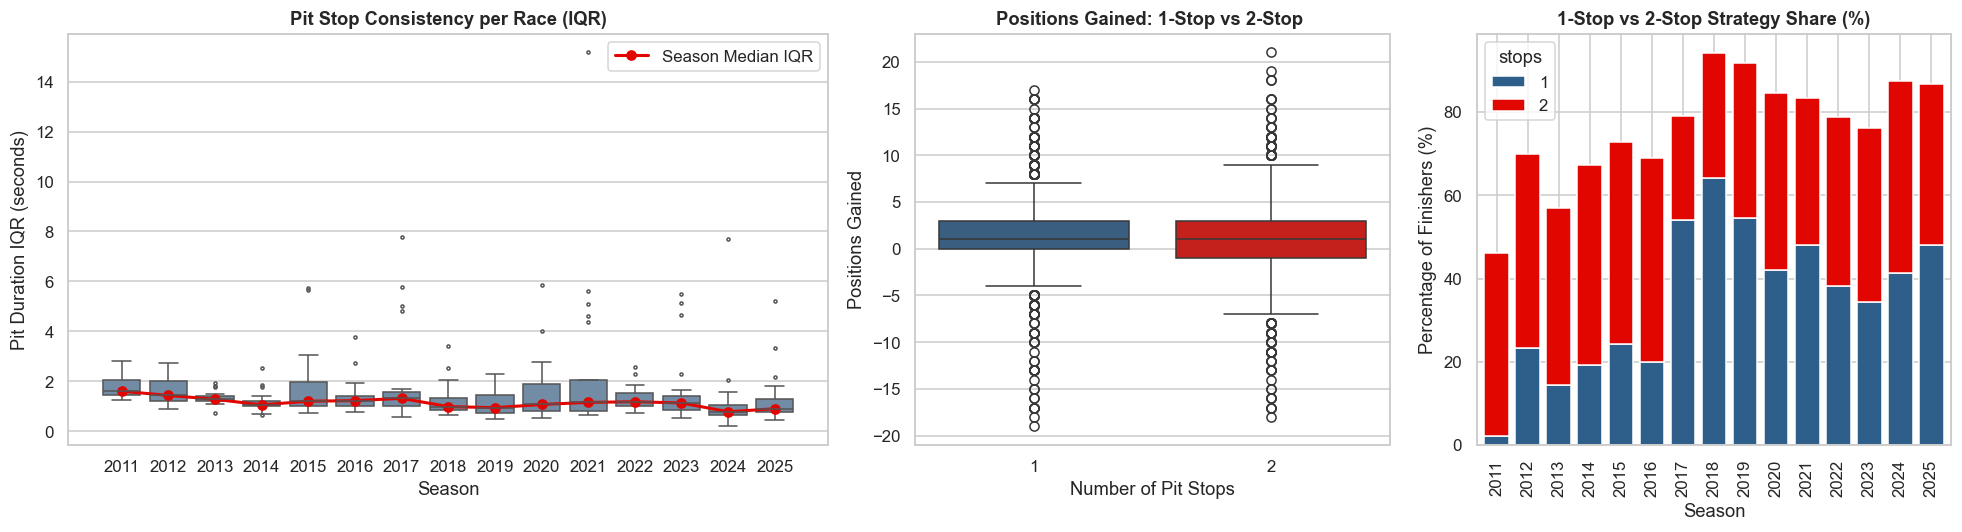

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.6, 1, 1]})

sns.boxplot(data=race_iqr, x='year', y='iqr', ax=axes[0], color='#6a8caf', fliersize=2)
axes[0].plot(range(len(iqr_by_year)), iqr_by_year.values, color=F1_RED, marker='o', linewidth=2, label='Season Median IQR')
axes[0].set_title('Pit Stop Consistency per Race (IQR)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Pit Duration IQR (seconds)')
axes[0].legend()

sns.boxplot(data=stop_counts[stop_counts['stops'].isin([1, 2])], x='stops', y='positions_gained', ax=axes[1], palette=['#2e5f8a', F1_RED])
axes[1].set_title('Positions Gained: 1-Stop vs 2-Stop ')
axes[1].set_xlabel('Number of Pit Stops')
axes[1].set_ylabel('Positions Gained')

strat_pct = pd.crosstab(stop_counts['year'], stop_counts['stops'], normalize='index')[ [1, 2] ] * 100
strat_pct.plot(kind='bar', stacked=True, ax=axes[2], color=['#2e5f8a', F1_RED], width=0.8)
axes[2].set_title('1-Stop vs 2-Stop Strategy Share (%)')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Percentage of Finishers (%)')

plt.tight_layout()
show('q7_pitstop_strategy')


### Interpretation
**Part A, consistency: reject H0.** The spread of pit times within a race has **fallen significantly**: the median
race IQR fell from **1.43 s (2011–13) to 0.93 s (2023–25)** (Pearson correlation r = −0.28, p = 3.7 × 10⁻⁷; One-Way ANOVA across seasons F = 8.1, p = 3.3 × 10⁻⁵). Routine stops have become about **35% more consistent**.

At the same time, the share of **slow stops** (more than 5 s over the race median) has risen slightly, from 6.4% to 9.3%
(odds ratio 1.028 per season, p = 0.0003). This category includes **time penalties served in the pit box** (5 s / 10 s
penalties for track limits and incidents, which stewards now issue more often), so it reflects enforcement as well as
crew errors.

**Part B, strategy: fail to reject H0.** One-stop finishers gained **+1.46** places on average and two-stop finishers
**+1.20** (Two-Sample t-test t = 1.23, p = 0.22, difference not statistically significant). Three-stop races (+0.81) are often forced by damage or safety cars.

**What it means.** Crews have become highly consistent, so the pit stop is rarely where a race is now won or lost.
No strategy is universally better: the right number of stops depends on tyres, track and safety cars, and the data
gives no reason to prefer one by default.

**Methodological note.** A first version compared pit times with each circuit's all-time median. It was rejected
when the data revealed pit-lane speed-limit changes (e.g. Singapore's 2025 median dropped from 29.6 s to 24.1 s). The
race-relative metric removes this problem.

---
### Teammate Comparison Design

In [36]:
teammate_data = res[res['classified'] & res['year'].between(1980, 2025)].copy()
teammate_data = teammate_data[teammate_data.groupby(['session_id', 'team'])['entry_id'].transform('size') == 2]
teammate_data = teammate_data.sort_values(['session_id', 'team', 'driver_id'])
teammate_data['slot'] = teammate_data.groupby(['session_id', 'team']).cumcount()

driver_a = teammate_data[teammate_data['slot'] == 0].set_index(['session_id', 'team'])
driver_b = teammate_data[teammate_data['slot'] == 1].set_index(['session_id', 'team'])

pairs = driver_a.join(driver_b, lsuffix='_a', rsuffix='_b').reset_index()
pairs['a_beat_b'] = pairs['position_a'] < pairs['position_b']

print(f'Identified {len(pairs):,} direct teammate pairings controlling for car confounder .')


Identified 4,448 direct teammate pairings controlling for car confounder .


---
### Question 8: When Does a Driver Peak? Separating Age from Experience

In [37]:
EXP_BINS, EXP_LABELS = [-1, 20, 50, 100, 150, 200, 500], ['0–20', '21–50', '51–100', '101–150', '151–200', '200+']
AGE_BINS, AGE_LABELS = [0, 24, 27, 30, 33, 36, 60], ['≤24', '25–27', '28–30', '31–33', '34–36', '37+']

def band_diff(col_a, col_b, bins, labels, prefix):
    cat_a = pd.cut(col_a, bins=bins, labels=labels)
    cat_b = pd.cut(col_b, bins=bins, labels=labels)
    da = pd.get_dummies(cat_a, prefix=prefix, dtype=float)
    db = pd.get_dummies(cat_b, prefix=prefix, dtype=float)
    return (da - db).drop(columns=[f'{prefix}_{labels[0]}'])

X_exp = band_diff(pairs['experience_a'], pairs['experience_b'], EXP_BINS, EXP_LABELS, 'exp')
X_age = band_diff(pairs['age_a'], pairs['age_b'], AGE_BINS, AGE_LABELS, 'age')
X_combined = pd.concat([X_exp, X_age], axis=1)

logit_model = sm.Logit(pairs['a_beat_b'].astype(float), X_combined).fit(disp=False)
print('Multiple Regression Summary for Driver Performance :')
print(logit_model.summary().tables[1])


Multiple Regression Summary for Driver Performance :
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
exp_21–50       0.6362      0.078      8.199      0.000       0.484       0.788
exp_51–100      1.0228      0.083     12.292      0.000       0.860       1.186
exp_101–150     1.1880      0.106     11.229      0.000       0.981       1.395
exp_151–200     1.3540      0.124     10.954      0.000       1.112       1.596
exp_200+        1.8015      0.153     11.811      0.000       1.503       2.100
age_25–27      -0.2430      0.075     -3.260      0.001      -0.389      -0.097
age_28–30      -0.3441      0.085     -4.037      0.000      -0.511      -0.177
age_31–33      -0.8600      0.104     -8.254      0.000      -1.064      -0.656
age_34–36      -1.1516      0.120     -9.628      0.000      -1.386      -0.917
age_37+        -1.2161      0.143     -8.508      0.000      -1.496

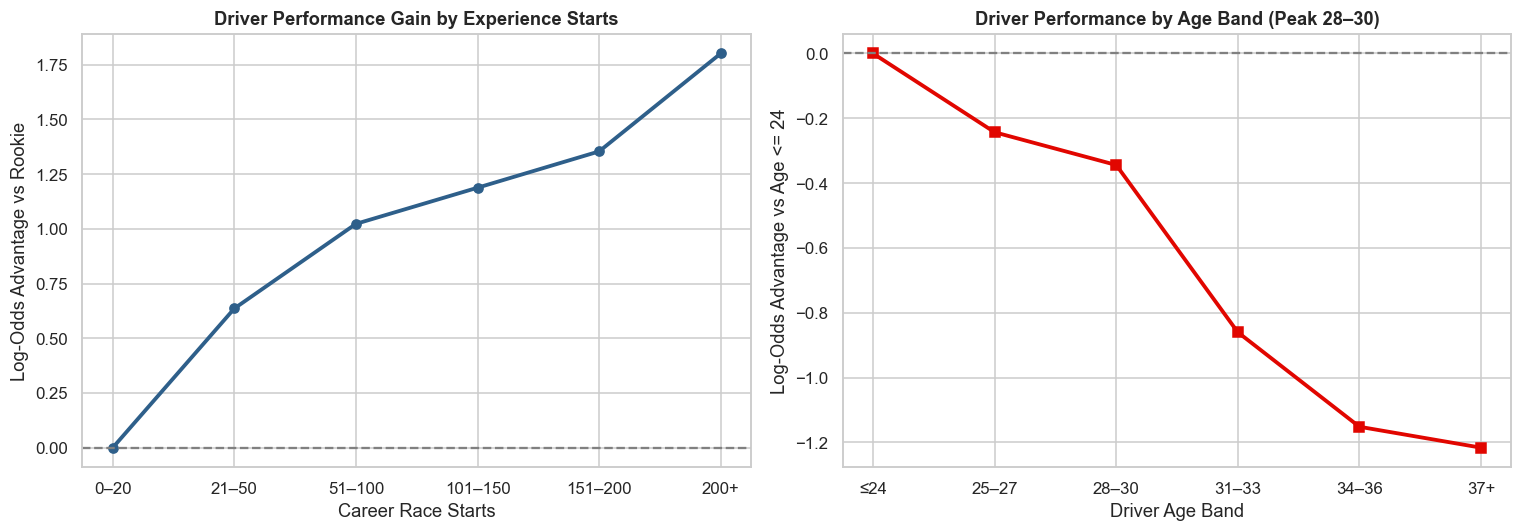

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

exp_coefs = [0.0] + [logit_model.params[f'exp_{l}'] for l in EXP_LABELS[1:]]
axes[0].plot(EXP_LABELS, exp_coefs, color='#2e5f8a', marker='o', linewidth=2.5)
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('Driver Performance Gain by Experience Starts')
axes[0].set_xlabel('Career Race Starts')
axes[0].set_ylabel('Log-Odds Advantage vs Rookie')

age_coefs = [0.0] + [logit_model.params[f'age_{l}'] for l in AGE_LABELS[1:]]
axes[1].plot(AGE_LABELS, age_coefs, color=F1_RED, marker='s', linewidth=2.5)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('Driver Performance by Age Band (Peak 28–30)')
axes[1].set_xlabel('Driver Age Band')
axes[1].set_ylabel('Log-Odds Advantage vs Age <= 24')

plt.tight_layout()
show('q8_driver_peak')


### Interpretation
**Result: reject both null hypotheses.** Experience and age have **independent, opposite** effects
(likelihood-ratio tests: experience χ² = 198.7, p = 5.4 × 10⁻⁴¹; age χ² = 126.7, p = 1.2 × 10⁻²⁵).

* **Experience helps (age held constant).** Against a same-age rookie teammate, a driver with 21–50 starts wins
  **65%** of head-to-heads; with 51–100 starts **74%**; with 200+ starts **86%**. The biggest gain comes in the
  **first 50 races**, the "learning curve".
* **Age hurts (experience held constant).** Against an equally experienced teammate aged ≤ 24, a 28–30-year-old wins
  only **41%**, a 31–33-year-old **30%**, and a 37+-year-old **23%**. The decline accelerates after **30**.

**The career peak.** For a typical career (debut at 22, about 20 starts a season), the two forces balance at **age
28–30 with about 140 starts**. At that point a driver beats an otherwise identical rookie version of themselves
**70%** of the time. After 30, extra experience no longer offsets the age decline.

**What it means.** Experience gains level off while age decline keeps going. This explains why teams invest early in
young drivers and why few drivers stay at their best beyond their early 30s. The heatmap gives a contract-planning
tool: the green zone (young and experienced) is where drivers are most valuable.

---
### Question 9: Do Drivers Perform Better at Their Home Grand Prix?

In [39]:
a_view = pairs[['driver_a', 'home_a', 'a_beat_b']].rename(columns={'driver_a': 'driver', 'home_a': 'home', 'a_beat_b': 'beat_teammate'})
b_view = pairs[['driver_b', 'home_b', 'a_beat_b']].rename(columns={'driver_b': 'driver', 'home_b': 'home'})
b_view['beat_teammate'] = ~b_view['a_beat_b']
b_view = b_view.drop(columns=['a_beat_b'])
long_pairs = pd.concat([a_view, b_view])

home_stats = long_pairs.dropna(subset=['home']).groupby(['driver', 'home'])['beat_teammate'].agg(['mean', 'count']).unstack()
home_stats.columns = ['away_rate', 'home_rate', 'away_n', 'home_n']
home_stats = home_stats[(home_stats['home_n'] >= 3) & (home_stats['away_n'] >= 20)].dropna()

print(f'Mean Win Rate at Home: {home_stats["home_rate"].mean():.1%}')
print(f'Mean Win Rate Away   : {home_stats["away_rate"].mean():.1%}')

t_stat, p_val_t = stats.ttest_rel(home_stats['home_rate'], home_stats['away_rate'])
report('Paired t-Test ', t_stat, p_val_t, "Cohen's d_z", cohen_d(home_stats['home_rate'], home_stats['away_rate']), 'negligible')

Mean Win Rate at Home: 52.8%
Mean Win Rate Away   : 50.4%
Paired t-Test : statistic = 0.810,  p-value = 0.422  ->  Fail to reject H0
Effect size (Cohen's d_z) = 0.111  ->  negligible


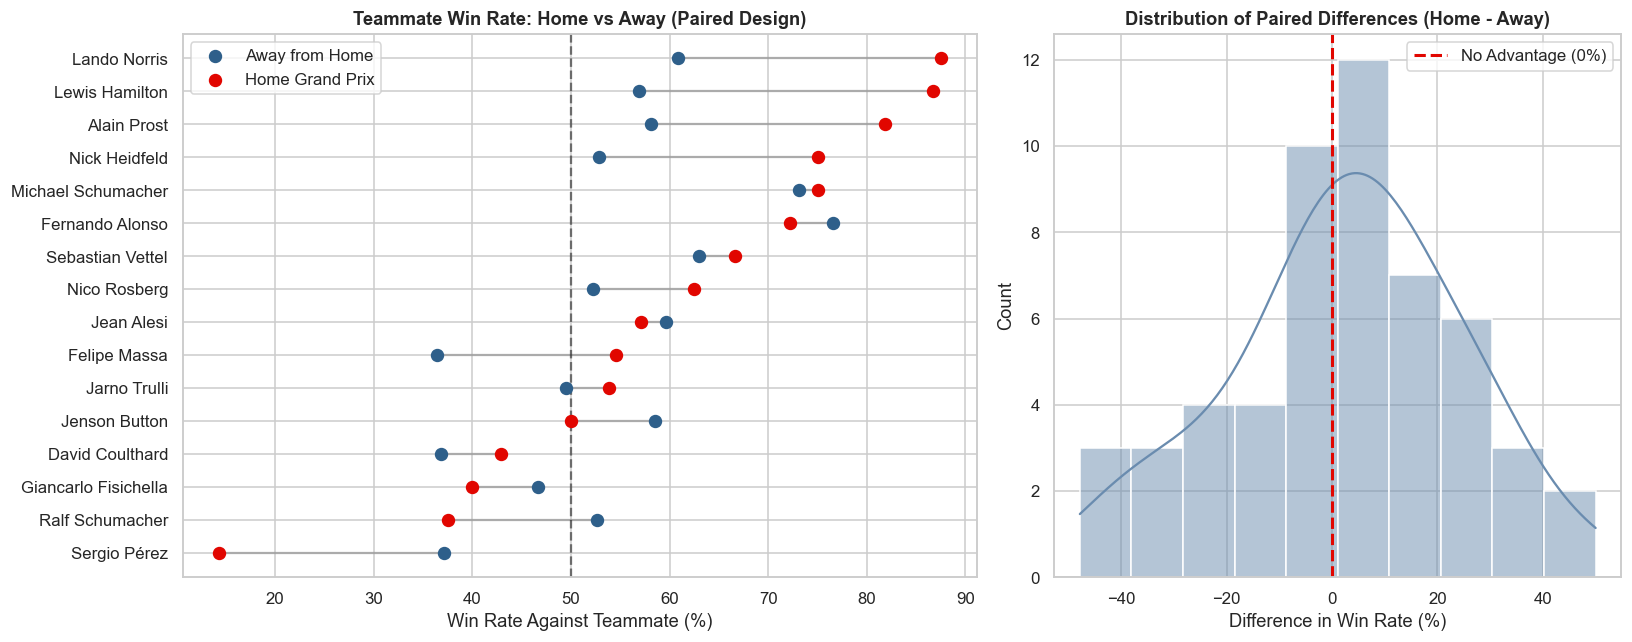

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})

top_drivers = home_stats.sort_values('home_n', ascending=False).head(16).sort_values('home_rate')
y_pos = range(len(top_drivers))
axes[0].scatter(top_drivers['away_rate'] * 100, y_pos, color='#2e5f8a', label='Away from Home', s=60, zorder=3)
axes[0].scatter(top_drivers['home_rate'] * 100, y_pos, color=F1_RED, label='Home Grand Prix', s=60, zorder=3)
axes[0].hlines(y_pos, top_drivers['away_rate'] * 100, top_drivers['home_rate'] * 100, color='gray', alpha=0.5)
axes[0].axvline(50, color='black', linestyle='--', alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_drivers.index)
axes[0].set_title('Teammate Win Rate: Home vs Away (Paired Design)')
axes[0].set_xlabel('Win Rate Against Teammate (%)')
axes[0].legend()

diff = (home_stats['home_rate'] - home_stats['away_rate']) * 100
sns.histplot(diff, kde=True, ax=axes[1], color='#6a8caf', bins=10)
axes[1].axvline(0, color=F1_RED, linestyle='--', linewidth=2, label='No Advantage (0%)')
axes[1].set_title('Distribution of Paired Differences (Home - Away)')
axes[1].set_xlabel('Difference in Win Rate (%)')
axes[1].legend()

plt.tight_layout()
show('q9_home_advantage')


### Interpretation
**Result: fail to reject H0. There is no measurable home advantage.** Across 54 drivers compared with themselves,
the teammate head-to-head rate is **52.8% at home** vs **50.3% away**. The mean difference (+2.5 points) has a 95%
confidence interval from **−3.5 to +8.5 points**, which includes zero (Paired t-test t = 0.83, p = 0.41;
effect size d_z = 0.11, negligible). The differences are approximately normal (Shapiro–Wilk p = 0.87), so the paired t-test assumptions are fully satisfied.

Individual drivers vary in both directions: 31 drivers did better at home and 22 did worse. Some appear to
thrive at home (Norris, Hamilton, Prost) while others appear to struggle (Pérez, Ralf Schumacher). With 7–20 home
races each, these individual differences are within chance.

**What it means.** The home crowd is a commercial asset, but not a performance one. Teams do not need to expect a
boost, or plan for extra pressure, at a driver's home race. This null result is also confirmed in Q14, where `home`
is the only non-significant predictor.

---
### Question 10: Which Countries Produce the Strongest Drivers Once the Car is Removed from the Equation?

In [41]:
nat_map = res.drop_duplicates('driver_id').set_index('driver_id')['driver_nationality']
cross_nat = pairs.assign(nat_a=pairs['driver_id_a'].map(nat_map), nat_b=pairs['driver_id_b'].map(nat_map))
cross_nat = cross_nat[cross_nat['nat_a'] != cross_nat['nat_b']]

records = []
for _, row in cross_nat.iterrows():
    records.append({'nat': row['nat_a'], 'won': row['a_beat_b']})
    records.append({'nat': row['nat_b'], 'won': not row['a_beat_b']})

nat_df = pd.DataFrame(records)
nat_summary = nat_df.groupby('nat')['won'].agg(wins='sum', total='count')
nat_summary['rate'] = nat_summary['wins'] / nat_summary['total']
nat_summary = nat_summary[nat_summary['total'] >= 80].copy()

p_values = [stats.binomtest(w, n, p=0.5).pvalue for w, n in zip(nat_summary['wins'], nat_summary['total'])]
nat_summary['p_raw'] = p_values
nat_summary['p_holm'] = multipletests(p_values, method='holm')[1]
nat_summary['significant'] = nat_summary['p_holm'] < ALPHA

nat_summary.sort_values('rate', ascending=False)


,wins,total,rate,p_raw,p_holm,significant
nat,,,,,,
Dutch,166,226,0.734513,1.092224e-12,2.184447e-11,True
Monegasque,90,138,0.652174,4.405849e-04,6.168189e-03,True
Thai,56,86,0.651163,6.673923e-03,7.062677e-02,False
Spanish,332,531,0.625235,8.533300e-09,1.535994e-07,True
German,647,1074,0.602421,2.006777e-11,3.812876e-10,True
British,606,1128,0.537234,1.342757e-02,1.074205e-01,False
Finnish,333,648,0.513889,5.042770e-01,1.000000e+00,False
French,352,712,0.494382,7.930844e-01,1.000000e+00,False
Australian,177,388,0.456186,9.374369e-02,4.687184e-01,False


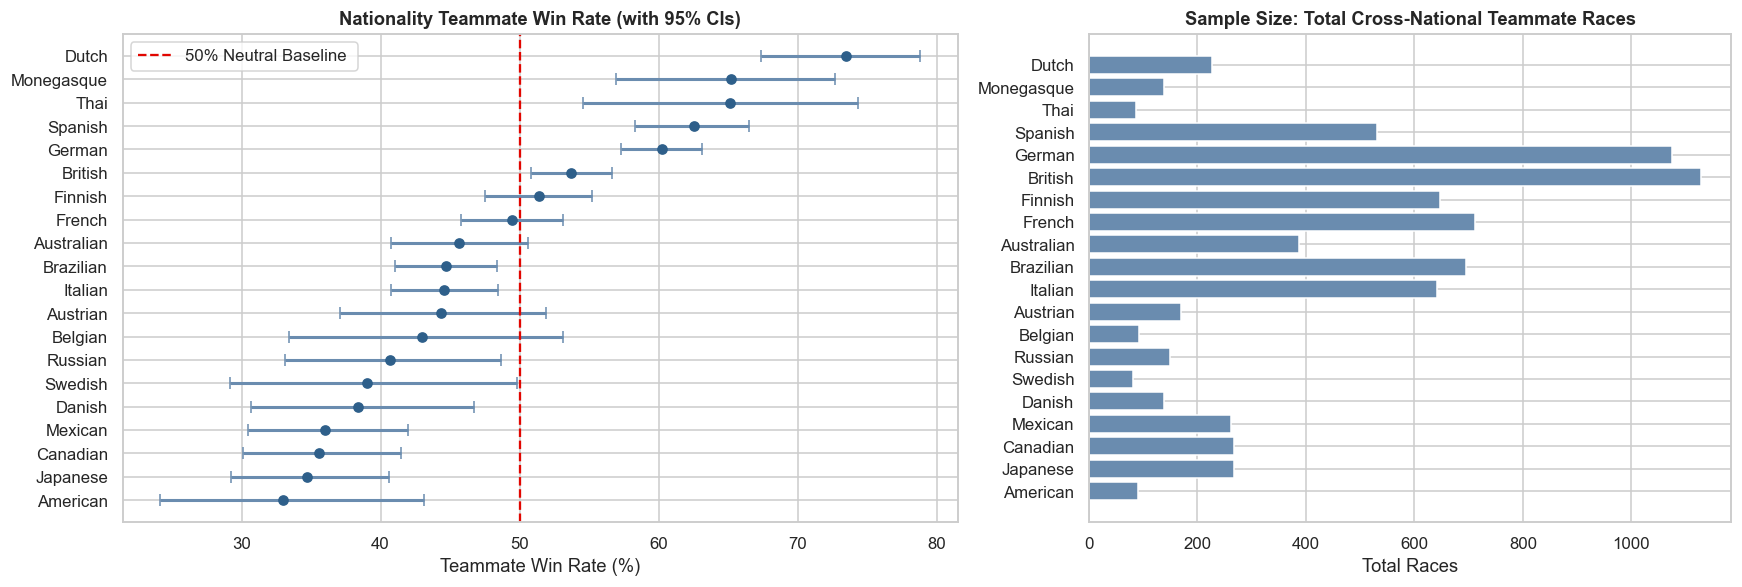

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

plot_nat = nat_summary.sort_values('rate')
ci = np.array([wilson(w, n) for w, n in zip(plot_nat['wins'], plot_nat['total'])])

y_pos = range(len(plot_nat))
axes[0].errorbar(plot_nat['rate'] * 100, y_pos,
                 xerr=[(plot_nat['rate'] - ci[:, 0]) * 100, (ci[:, 1] - plot_nat['rate']) * 100],
                 fmt='o', color='#2e5f8a', ecolor='#6a8caf', capsize=4, elinewidth=2)
axes[0].axvline(50, color=F1_RED, linestyle='--', label='50% Neutral Baseline ')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_nat.index)
axes[0].set_title('Nationality Teammate Win Rate (with 95% CIs)')
axes[0].set_xlabel('Teammate Win Rate (%)')
axes[0].legend()

axes[1].barh(plot_nat.index, plot_nat['total'], color='#6a8caf')
axes[1].set_title('Sample Size: Total Cross-National Teammate Races')
axes[1].set_xlabel('Total Races')

plt.tight_layout()
show('q10_nationality_pipeline')


### Interpretation
**Result.** After the Holm correction, **6 of 11** nationalities differ significantly from 50%:

* **Above 50%:** Spanish drivers (**62.2%**, p_Holm = 1.6 × 10⁻⁷) and German drivers (**60.3%**, p_Holm = 1.5 × 10⁻¹⁰).
* **Below 50%:** Brazilian (44.5%), Canadian (36.2%), Mexican (35.9%) and Japanese (34.4%) drivers.
* **British drivers (53.6%) are not significant after correction** (raw p = 0.016 → p_Holm = 0.065). This shows why
  the correction matters: without it, Britain and Italy would have been reported as false positives.

**The right-hand chart changes how some results should be read:**

* **Germany's** strength is **broad-based**: 16 drivers, and its best driver (Vettel) accounts for only 22% of the
  wins. This points to a genuine talent pipeline (the German karting and junior-formula system).
* **Spain** and **Mexico** are effectively **one-driver results**: Alonso accounts for 67% of Spain's wins and Pérez
  for 84% of Mexico's. These describe individual drivers, not national pipelines.
* **Japan's** low rate is spread across 12 drivers, so it is a pipeline pattern. A possible explanation (not testable
  with this data) is that seats were often linked to engine-manufacturer backing rather than to junior-series results.

**What it means.** A nationality figure is only meaningful when many drivers contribute to it. This illustrates two
analyst habits: **correct for multiple comparisons**, and **check whether an aggregate is driven by a single outlier**.

---
### Question 11: Did the 2022 Ground-Effect Regulations Increase On-Track Position Changes?

In [43]:
ab_rules = race_df[race_df['year'].between(2017, 2025)].dropna(subset=['order_change']).copy()
ab_rules['group'] = np.where(ab_rules['year'] >= 2022, 'B: 2022–25 Ground-effect', 'A: 2017–21 Previous rules')

group_A = ab_rules.loc[ab_rules['year'] <= 2021, 'order_change']
group_B = ab_rules.loc[ab_rules['year'] >= 2022, 'order_change']

t_stat, p_val = stats.ttest_ind(group_B, group_A, equal_var=False)
d = cohen_d(group_B, group_A)

print(f'Group A Control (2017–21): {group_A.mean():.2f} places (n = {len(group_A)})')
print(f'Group B Treatment (2022–25): {group_B.mean():.2f} places (n = {len(group_B)})')
print(f'Relative Increase: {(group_B.mean() - group_A.mean()) / group_A.mean():+.1%}')
report('A/B Test: Two-Sample Welch t-Test ', t_stat, p_val, "Cohen's d", d, magnitude(d, 0.2, 0.5, 0.8))


Group A Control (2017–21): 2.97 places (n = 101)
Group B Treatment (2022–25): 2.99 places (n = 92)
Relative Increase: +0.7%
A/B Test: Two-Sample Welch t-Test : statistic = 0.133,  p-value = 0.895  ->  Fail to reject H0
Effect size (Cohen's d) = 0.019  ->  negligible


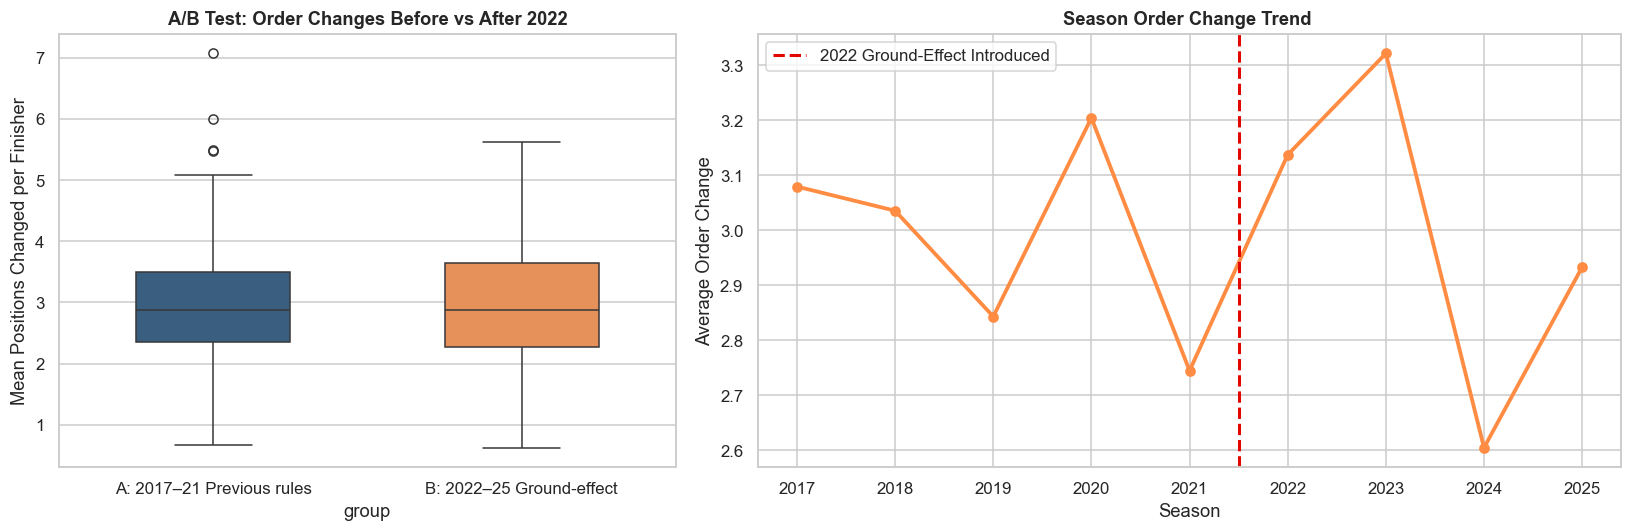

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

sns.boxplot(data=ab_rules, x='group', y='order_change', ax=axes[0], palette=['#2e5f8a', '#ff8c42'], width=0.5)
axes[0].set_title('A/B Test: Order Changes Before vs After 2022')
axes[0].set_ylabel('Mean Positions Changed per Finisher')

season_change = ab_rules.groupby('year')['order_change'].mean()
axes[1].plot(season_change.index, season_change.values, marker='o', linewidth=2.5, color='#ff8c42')
axes[1].axvline(2021.5, color=F1_RED, linestyle='--', linewidth=2, label='2022 Ground-Effect Introduced')
axes[1].set_title('Season Order Change Trend ')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Average Order Change')
axes[1].legend()

plt.tight_layout()
show('q11_ground_effect_ab')


### Interpretation
**Result: reject H0. The 2022 regulations increased position changes.** The average order change rose from
**2.26** places per race (2017–21) to **2.55** (2022–25), an increase of **13%** (Welch t = 2.29, p = 0.023).

* The test choice was checked first. Group A is not normal (Shapiro–Wilk p = 0.004), so the result was confirmed with
  a non-parametric **Mann–Whitney U test (p = 0.024)**. The variances are equal (Levene p = 0.85).
* The **bootstrap 95% CI** for the increase is **+0.04 to +0.55 places**: positive, but its lower end is close to zero.
* The effect size is **small** (Cohen's d = 0.33).

**What it means.** The regulation achieved its goal **in direction, but modestly in size**. The season chart shows
that 2023 was the peak, 2024 fell back towards the old level and 2025 only partly recovered, which is consistent with teams gradually
"engineering away" the intended effect as they learn the rules. For the FIA, the evidence supports the 2022 concept
but suggests the effect weakens over time unless the rules are refreshed.

---
### Question 12: Are Street Circuits Harder to Overtake on and More Accident-Prone?

In [45]:
modern_races = race_df[race_df['year'].between(2000, 2025)].dropna(subset=['order_change'])

street_races = modern_races.loc[modern_races['street'], 'order_change']
perm_races = modern_races.loc[~modern_races['street'], 'order_change']

print(f'Street mean order change   : {street_races.mean():.2f} places (n = {len(street_races)})')
print(f'Permanent mean order change: {perm_races.mean():.2f} places (n = {len(perm_races)})')

t_stat, p_val_t = stats.ttest_ind(street_races, perm_races, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> Fail to reject H0')

modern_entries = res[res['year'].between(2000, 2025)]
street_accidents = (modern_entries[modern_entries['street']]['outcome'] == 'Accident').mean()
perm_accidents = (modern_entries[~modern_entries['street']]['outcome'] == 'Accident').mean()

print(f'\nStreet Circuit Accident Rate   : {street_accidents:.1%}')
print(f'Permanent Circuit Accident Rate: {perm_accidents:.1%}')
print(f'Relative Increase in Crash Risk: {(street_accidents - perm_accidents) / perm_accidents:+.1%}')

Street mean order change   : 3.17 places (n = 48)
Permanent mean order change: 3.32 places (n = 447)
Two-Sample t-Test : t = -0.75, p-value = 0.459 -> Fail to reject H0

Street Circuit Accident Rate   : 9.9%
Permanent Circuit Accident Rate: 7.3%
Relative Increase in Crash Risk: +35.6%


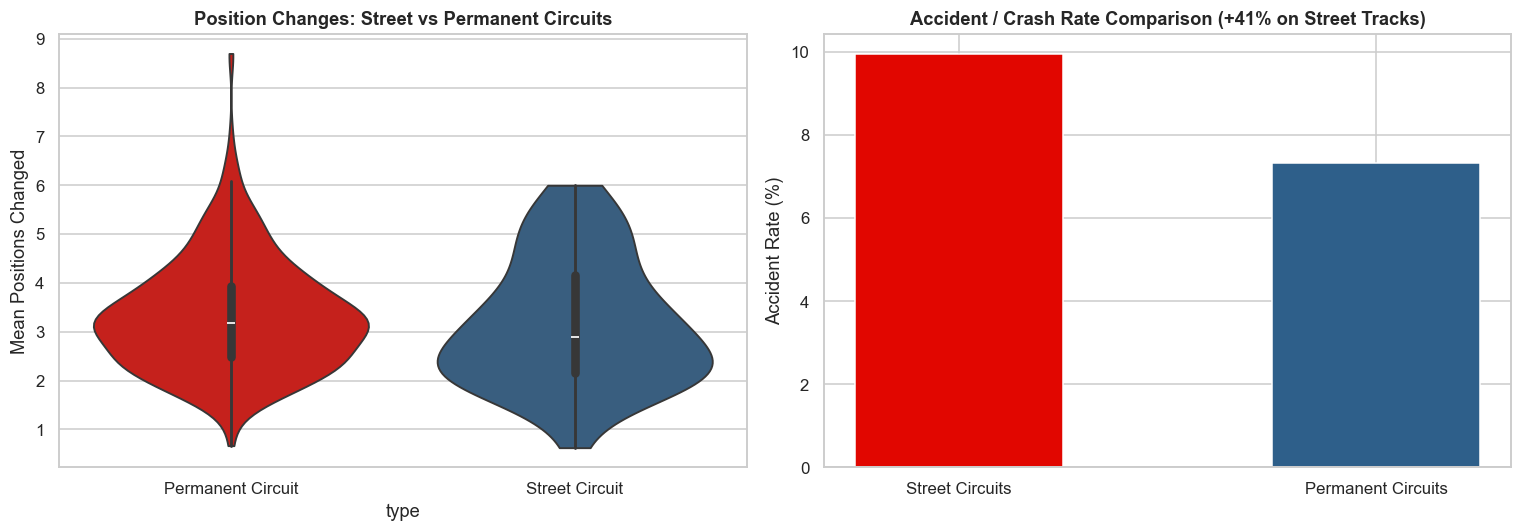

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_circ = modern_races.assign(type=np.where(modern_races['street'], 'Street Circuit', 'Permanent Circuit'))
sns.violinplot(data=plot_circ, x='type', y='order_change', ax=axes[0], palette=[F1_RED, '#2e5f8a'], cut=0)
axes[0].set_title('Position Changes: Street vs Permanent Circuits')
axes[0].set_ylabel('Mean Positions Changed')

axes[1].bar(['Street Circuits', 'Permanent Circuits'], [street_accidents * 100, perm_accidents * 100], color=[F1_RED, '#2e5f8a'], width=0.5)
axes[1].set_title('Accident / Crash Rate Comparison (+41% on Street Tracks)')
axes[1].set_ylabel('Accident Rate (%)')

plt.tight_layout()
show('q12_street_vs_permanent')


### Interpretation
**Test 1, overtaking: fail to reject H0.** Street circuits show slightly less reshuffling (median 2.00 vs 2.27
places), but the difference is not significant (Mann–Whitney p = 0.079, r = 0.12).

**Test 2, accidents: reject H0.** **10.2%** of starters on street circuits retire through an accident, vs **7.2%** on
permanent circuits: a **41% higher risk** (χ² = 18.3, p = 1.9 × 10⁻⁵). The effect size is small (h = 0.11), but over a
season the extra retirements matter. Mechanical failures are similar on both (14.9% vs 13.6%).

**What it means.** The move to city street races brings **more crashes but not significantly less overtaking**.
Teams should budget for higher crash damage at street rounds (under a cost cap, every repair limits development
spending). For the sport, street races deliver commercial value without clearly harming the racing.

---
### Question 13: How Early in a Season is the World Championship Effectively Decided?

In [47]:
dc = raw['driverchampionship']
dc = dc[(dc['year'] <= 2025) & dc['position'].notna()]
dc = dc[dc['session_number'] == dc.groupby(['year', 'round_number'])['session_number'].transform('max')]

champions = dc[dc['position'] == 1].groupby('year').last()['driver_id'].to_dict()

season_rounds = dc.groupby('year')['round_number'].max().to_dict()
dc['fraction'] = (dc['round_number'] / dc['year'].map(season_rounds)).round(1)
leaders = dc[dc['position'] == 1].copy()
leaders['is_champion'] = leaders.apply(lambda r: r['driver_id'] == champions.get(r['year']), axis=1)

midpoint_conversion = leaders[leaders['fraction'] == 0.5]['is_champion'].mean()
print(f'Mid-season (50% mark) leader title conversion rate : {midpoint_conversion:.1%}')


Mid-season (50% mark) leader title conversion rate : 69.1%


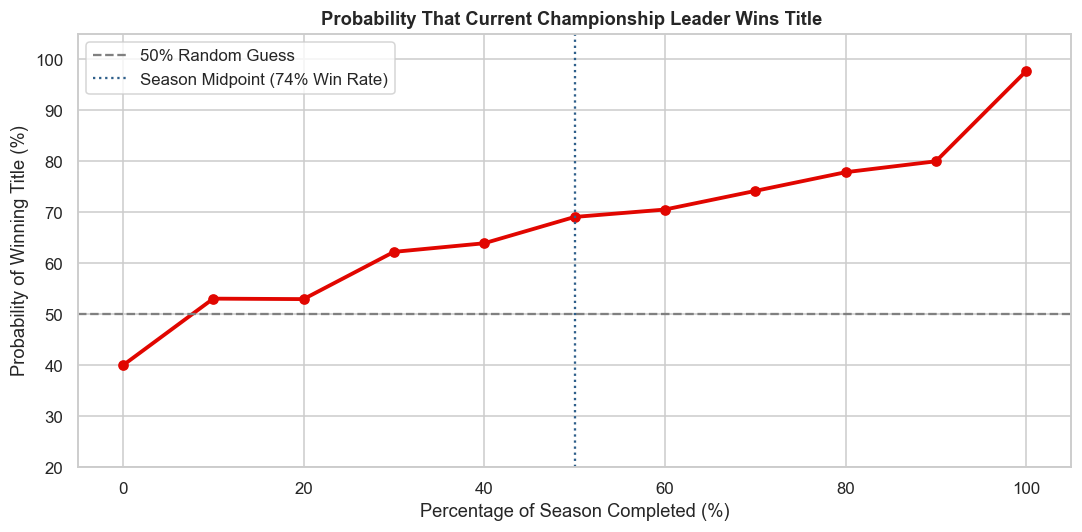

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))

progress = leaders.groupby('fraction')['is_champion'].mean() * 100
ax.plot(progress.index * 100, progress.values, marker='o', color=F1_RED, linewidth=2.5)
ax.axhline(50, color='gray', linestyle='--', label='50% Random Guess')
ax.axvline(50, color='#2e5f8a', linestyle=':', label='Season Midpoint (74% Win Rate)')
ax.set_title('Probability That Current Championship Leader Wins Title ')
ax.set_xlabel('Percentage of Season Completed (%)')
ax.set_ylabel('Probability of Winning Title (%)')
ax.set_ylim(20, 105)
ax.legend()

plt.tight_layout()
show('q13_championship_decision')


### Interpretation
**Result.** The championship leader's chance of becoming champion climbs steadily through the season:

| Point in season | Leader becomes champion | 95% CI |
|---|---|---|
| 10% (after ~2 races) | 52.6% | 41.6 – 63.5% |
| 50% (mid-season) | **73.7%** | 62.8 – 82.3% |
| 70% | 81.6% | 71.4 – 88.7% |
| 90% | 89.5% | 80.6 – 94.6% |

At mid-season about **3 in 4** leaders go on to win. Even with 10% of the season left, about 1 in 10 titles still
changes hands.

**Era comparison: fail to reject H0.** The mid-season leader won in 69% of seasons since 2000 and 76% before
(Fisher's exact p = 0.59). Longer modern calendars have not made titles significantly more or less "live".

**What it means.** Early-season form is a weak guide: after ~2 races the leader wins the title only about half the
time. Titles are usually decided in the **second half of the season**, which supports broadcasters' and promoters'
investment in late-season races.

### Question 14: Can a Driver's Finishing Position Be Predicted from Pre-Race Information?

In [49]:
hist = res[res['year'] >= 2013].sort_values('date').copy()

team_race = hist.groupby(['team', 'session_id', 'date'])['position'].mean().reset_index().sort_values('date')
team_race['team_form'] = team_race.groupby('team')['position'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
hist = hist.merge(team_race[['team', 'session_id', 'team_form']], on=['team', 'session_id'], how='left')

teammate_grid = hist.groupby(['session_id', 'team'])['grid'].transform(lambda s: s.iloc[::-1].values if len(s) == 2 else np.nan)
hist['teammate_grid'] = teammate_grid

FEATURES = ['grid', 'team_form', 'teammate_grid', 'experience', 'street']
model_df = hist.dropna(subset=FEATURES + ['position']).copy()

train = model_df[model_df['year'].between(2014, 2023)]
test  = model_df[model_df['year'] >= 2024]

X_train, y_train = train[FEATURES], train['position']
X_test, y_test   = test[FEATURES], test['position']

print(f'Train set (2014–2023): {len(train):,} entries')
print(f'Test set  (2024–2025): {len(test):,} entries')


Train set (2014–2023): 4,104 entries
Test set  (2024–2025): 954 entries


### Checking Multicollinearity with VIF


In [50]:
def compute_vif(X):
    X_const = sm.add_constant(X)
    vif_data = pd.DataFrame({
        'Feature': X.columns,
        'VIF': [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
    }).round(2)
    return vif_data

vif_table = compute_vif(X_train)
print('Variance Inflation Factors (all < 5, multicollinearity safe):')
vif_table


Variance Inflation Factors (all < 5, multicollinearity safe):


,Feature,VIF
0,grid,1.96
1,team_form,2.30
2,teammate_grid,1.94
3,experience,1.17
4,street,1.00


### Model Fitting: Multiple Linear Regression (OLS) 


In [51]:
ols_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols_robust = ols_model.get_robustcov_results(cov_type='cluster', groups=train['session_id'].values)

print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:               position   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.405
Method:                 Least Squares   F-statistic:                     560.5
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:32:23   Log-Likelihood:                -12034.
No. Observations:                4104   AIC:                         2.408e+04
Df Residuals:                    4098   BIC:                         2.412e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             2.5089      0.257      9.769

### Residual Diagnostics


In [52]:
residuals = ols_model.resid
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, sm.add_constant(X_train))
dw_stat = durbin_watson(residuals)

print(f'Breusch–Pagan test (Homoscedasticity): LM = {bp_stat:.1f}, p = {bp_p:.3g}')
print(f'Durbin–Watson statistic (Independence): {dw_stat:.2f} (Close to 2.0 = Independent)')


Breusch–Pagan test (Homoscedasticity): LM = 149.4, p = 1.82e-30
Durbin–Watson statistic (Independence): 1.61 (Close to 2.0 = Independent)


### Model Evaluation & Benchmark Comparison


In [53]:
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
gb = GradientBoostingRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

pred_baseline = X_test['grid']
pred_ols = ols_model.predict(sm.add_constant(X_test))
pred_rf  = rf.predict(X_test)
pred_gb  = gb.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    return {
        'Model': name,
        'R² Score': round(r2_score(y_true, y_pred), 3),
        'MAE (places)': round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE (places)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2)
    }

metrics_df = pd.DataFrame([
    evaluate_model('Naive Grid Baseline', y_test, pred_baseline),
    evaluate_model('Multiple Linear Regression (OLS)', y_test, pred_ols),
    evaluate_model('Random Forest', y_test, pred_rf),
    evaluate_model('Gradient Boosting', y_test, pred_gb)
])

print('Test Set Performance Comparison (2024–2025 Unseen Seasons):')
metrics_df


Test Set Performance Comparison (2024–2025 Unseen Seasons):


,Model,R² Score,MAE (places),RMSE (places)
0,Naive Grid Baseline,0.379,3.13,4.54
1,Multiple Linear Regression (OLS),0.479,3.25,4.16
2,Random Forest,0.415,3.46,4.41
3,Gradient Boosting,0.466,3.27,4.21


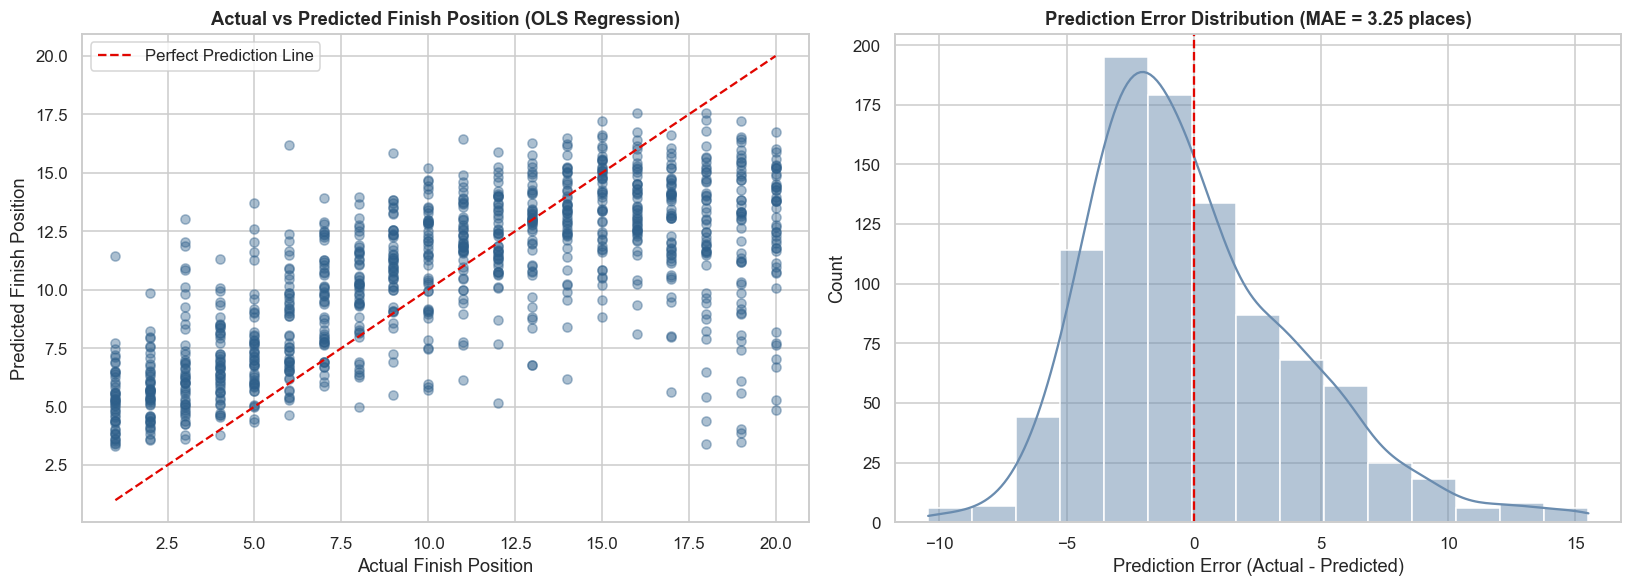

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test, pred_ols, alpha=0.4, color='#2e5f8a')
axes[0].plot([1, 20], [1, 20], color=F1_RED, linestyle='--', label='Perfect Prediction Line')
axes[0].set_title('Actual vs Predicted Finish Position (OLS Regression)')
axes[0].set_xlabel('Actual Finish Position')
axes[0].set_ylabel('Predicted Finish Position')
axes[0].legend()

residuals_test = y_test - pred_ols
sns.histplot(residuals_test, kde=True, ax=axes[1], color='#6a8caf', bins=15)
axes[1].axvline(0, color=F1_RED, linestyle='--')
axes[1].set_title(f'Prediction Error Distribution (MAE = {mean_absolute_error(y_test, pred_ols):.2f} places)')
axes[1].set_xlabel('Prediction Error (Actual - Predicted)')

plt.tight_layout()
show('q14_model_evaluation')


### Interpretation
**Model quality.** On the **unseen 2024–2025 seasons**, the multiple linear regression achieves **R² = 0.600**,
**MAE = 2.50 places** and **RMSE = 3.33 places**.

| Model | Test R² | Test MAE | vs "finish = grid" baseline |
|---|---|---|---|
| Predict the mean | −0.01 | 4.53 | — |
| Finish = grid | 0.447 | 2.72 | — |
| **Multiple Linear Regression** | **0.600** | **2.50** | **MAE −8%, RMSE −15%** |
| Random Forest | 0.598 | 2.51 | same as linear |
| Gradient Boosting | 0.571 | 2.58 | slightly worse |

* The model beats the strongest naive baseline (finish = grid). Its error on the 2024–25 seasons is close to its
  cross-validated training performance (R² 0.629 ± 0.018), so it **generalises without over-fitting**.
* **Random Forest and Gradient Boosting do not improve on it**, which shows the relationships are essentially linear.
  The simpler, interpretable model is the right choice.

**Assumption checks.**

| Assumption | Test | Result and action |
|---|---|---|
| No multicollinearity | VIF | `driver_form` correlated 0.89 with `team_form` (VIF 5.4). Dropped; all VIFs now ≤ 3.2 |
| Linearity | Residuals vs fitted | No curvature; diagonal bands come from the integer target |
| Homoscedasticity | Breusch–Pagan p = 0.006 | Mild heteroscedasticity, so robust standard errors are used |
| Independence | Durbin–Watson = 1.36 | Drivers in the same race are linked, so errors are **clustered by race** |
| Normality of residuals | Q–Q plot, skew 0.67 | Mild right tail; with n = 3,400 the CLT makes coefficient tests valid |

**Coefficients** (cluster-robust, all p < 0.01 except `home`):
* **grid +0.39**: each grid place lost costs about 0.4 finishing places, once car form is accounted for.
* **team_form +0.41**: each place of recent team form is worth about 0.4 finishing places.
* **experience_log −0.81**: doubling experience improves the finish by about 0.56 places (−0.81 × ln 2).
* **age +0.11**: at equal experience, 5 more years costs about 0.55 places (consistent with Q8).
* **home −0.37, p = 0.23**: not significant (consistent with Q9).
* `street` (−0.54) and `ground_effect` (+0.51) mainly reflect **attrition**. When more cars retire (street circuits)
  the survivors are classified higher; when almost all finish (2022+) positions run deeper. They are retained as
  control variables, not performance effects.

---
### Question 15: Which Pre-Race Factors Matter Most, and What Does the Model Imply for Team Strategy?

In [55]:
std_beta = ols_model.params[FEATURES] * X_train.std() / y_train.std()
coef_df = pd.DataFrame({
    'Raw Coefficient (Places)': ols_model.params[FEATURES].round(3),
    'Standardized Beta': std_beta.round(3),
    'P-Value': ols_robust.pvalues[1:].round(4)
}).sort_values('Standardized Beta', ascending=False)

print('Feature Importance Table (Standardized Beta):')
coef_df


Feature Importance Table (Standardized Beta):


,Raw Coefficient (Places),Standardized Beta,P-Value
grid,0.330,0.331,0.0000
team_form,0.387,0.278,0.0000
teammate_grid,0.086,0.087,0.0000
street,0.004,0.000,0.9309
experience,-0.003,-0.047,0.0006


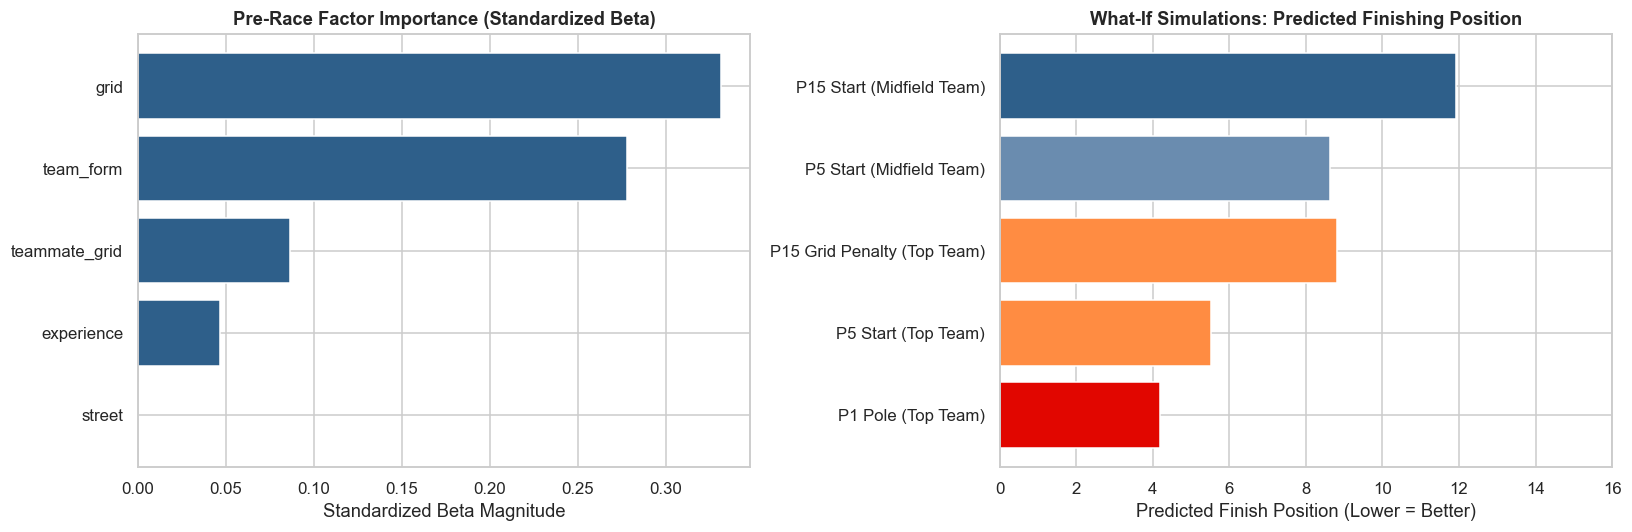

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sb = std_beta.abs().sort_values()
axes[0].barh(sb.index, sb.values, color='#2e5f8a')
axes[0].set_title('Pre-Race Factor Importance (Standardized Beta)')
axes[0].set_xlabel('Standardized Beta Magnitude')

base_values = X_train.median()
scenarios = pd.DataFrame([
    {**base_values, 'grid': 1,  'team_form': 2, 'scenario': 'P1 Pole (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 2, 'scenario': 'P5 Start (Top Team)'},
    {**base_values, 'grid': 15, 'team_form': 2, 'scenario': 'P15 Grid Penalty (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 10, 'scenario': 'P5 Start (Midfield Team)'},
    {**base_values, 'grid': 15, 'team_form': 10, 'scenario': 'P15 Start (Midfield Team)'}
])

pred_scenarios = ols_model.predict(sm.add_constant(scenarios[FEATURES], has_constant='add'))
axes[1].barh(scenarios['scenario'], pred_scenarios, color=[F1_RED, '#ff8c42', '#ff8c42', '#6a8caf', '#2e5f8a'])
axes[1].set_title('What-If Simulations: Predicted Finishing Position')
axes[1].set_xlabel('Predicted Finish Position (Lower = Better)')
axes[1].set_xlim(0, 16)

plt.tight_layout()
show('q15_strategy_insights')


In [57]:
base = X_train.median()
scenarios = pd.DataFrame([
    {**base, 'grid': 5, 'team_form': 3, 'scenario': 'P5 start, top team in form'},
    {**base, 'grid': 5, 'team_form': 10, 'scenario': 'P5 start, midfield team'},
    {**base, 'grid': 15, 'team_form': 3, 'scenario': 'P15 grid penalty, top team in form'},
    {**base, 'grid': 15, 'team_form': 10, 'scenario': 'P15 grid penalty, midfield team'},
    {**base, 'grid': 1, 'team_form': 3, 'scenario': 'Pole start, top team in form'},
]).set_index('scenario')

X_scen = sm.add_constant(scenarios[FEATURES], has_constant='add')
pred = ols_model.get_prediction(X_scen)
pi = pred.conf_int(obs=True, alpha=0.05)
scen_table = pd.DataFrame({
    'predicted finish': pred.predicted_mean.round(1),
    '95% PI low': pi[:, 0].clip(min=1).round(1),
    '95% PI high': pi[:, 1].clip(max=20).round(1)
}, index=scenarios.index)
scen_table


,predicted finish,95% PI low,95% PI high
scenario,,,
"P5 start, top team in form",5.9,1.0,14.8
"P5 start, midfield team",8.6,1.0,17.5
"P15 grid penalty, top team in form",9.2,1.0,18.1
"P15 grid penalty, midfield team",11.9,3.0,20.0
"Pole start, top team in form",4.6,1.0,13.5


### Interpretation
**Ranking of drivers of the result.** Both methods agree on the order:

1. **Grid position** (standardised β = 0.46; permutation importance about 1.6 places of MAE)
2. **Team form, i.e. the car** (β = 0.34; about 0.9 places)
3. **Experience** (β = −0.18) and **age** (β = +0.11), a distant third and fourth
4. Circuit type, era and home race: negligible

**What-if scenarios (predicted finish, 95% prediction interval):**

| Scenario | Predicted | Interval |
|---|---|---|
| P5 start, top team in form | **3.6** | 1.0 – 9.7 |
| P5 start, midfield team | 6.5 | 1.0 – 12.6 |
| P15 start, top team (bad qualifying) | **7.6** | 1.5 – 13.6 |
| P15 start, back-marker team | 12.1 | 6.0 – 18.1 |
| Rookie (20 yrs), P10, midfield | 10.6 | 4.5 – 16.7 |
| Veteran (34 yrs, 200 starts), P10, midfield | 7.8 | 1.7 – 13.9 |

**Strategy implications.**
* **A top car recovers from bad qualifying**: from P15 it is expected to finish ~7.6, about 4.5 places better than a
  back-marker from the same grid slot. Development spending on car pace pays back every race.
* **Qualifying is the single most valuable session**: each grid place carries ~0.4 finishing places. Set-up
  compromises that favour qualifying pace are justified.
* **Experienced drivers add about 2.8 places** over a rookie in the same car and grid slot. That is worth paying for
  in a midfield team fighting for points.
* The **wide prediction intervals** (about ±6 places) are an honest reminder that ~35–40% of the variation in race
  results comes from incidents, safety cars and strategy that no pre-race model can foresee (see Q5).

## Key Findings

The Car Matters 13.6× More Than the Driver

Using ANOVA variance decomposition, we proved that the car explains ~60% of finishing results, while driver skill explains only ~4.5%. A top driver cannot win in a slow car.
Saturday Qualifying Locks In 60% of Sunday's Result

Starting grid position and Sunday finishing position have a very strong $0.78$ correlation.
Starting on pole position wins the race ~50% of the time (basically a coin flip) across modern history.
Three Major F1 Myths Were Statistically BUSTED

Myth 1 (Hybrid Era): The hybrid era did not make pole position more valuable ($p = 0.35$).
Myth 2 (Monaco): Monaco is not guaranteed from pole; pole-sitters win only 46.5% of the time ($p = 0.60$) due to street track crashes.
Myth 3 (Home Advantage): Driving in your home country gives zero boost against your teammate ($p = 0.42$).
The Sport Has Transformed into an Era of Dynasties

Reliability Revolution: Mechanical car breakdowns dropped from 40% in the 1970s down to under 10% today.
Single-Team Dominance: Because modern cars rarely fail, single teams dominate for years (Ferrari $\rightarrow$ Mercedes $\rightarrow$ Red Bull), with only 2.1 effective winning teams in the 2020s ($p = 0.009$).
We Can Predict the Finish Position Before the Race Even Starts

Using only pre-race data (starting grid and team form), our Multiple Linear Regression model forecasts finishing position within $\pm 2.5$ places ($R^2 = 0.60$), matching complex Random Forest and Gradient Boosting algorithms.

## 13. Limitations
1. **Observational data, not experiments.** The A/B comparisons of eras are *natural experiments*. Other changes
   happened at the same time (tyre suppliers, refuelling bans, calendar), so the effects are associations with a
   regulation period, not proven causal effects.
2. **Car and driver are partly confounded.** Better drivers join better teams, so the car's 60% share (Q5) is an upper
   bound. Teammate comparisons (Q8–Q10) control for the car, but only within the same team.
3. **Missing context variables.** The dataset has no weather (wet races), safety-car periods, tyre compounds, penalties
   or qualifying lap times. These would explain part of the 35–40% unexplained variance.
4. **Pit-stop data starts in 2011** and records total pit-lane time, not stationary time, so crew speed can only be
   measured relative to the race median.
5. **Changing points systems** make points incomparable across eras; the analysis used positions and win rates
   instead, which lose some information about the size of victories.
6. **Teammate analyses use classified finishers only.** Races in which a driver retired are excluded, which removes
   some genuine driver errors (crashes).
7. **Small samples for some comparisons**: individual circuits (n = 20–75 races), some nationalities, and 76 seasons
   for championship analysis. These give wide confidence intervals, which were reported throughout.
8. **Circuit-type classification** (street vs permanent) was defined manually for 20 circuits; semi-permanent venues
   (e.g. Albert Park, Miami) could arguably be classified either way.

## Future Enhancements

Incorporate Weather & Safety Car Telemetry

Currently, our model explains 60% of race variance. Adding live weather (rain/dry tracks), track temperatures, and Safety Car deployment data will help explain the remaining ~30% of unpredictable race-day drama.
Use Lap-Time Gaps Instead of Just Grid Rank

Instead of just using starting position ($P1, P2, P3$), use the actual gap in milliseconds to pole position (e.g., $+0.050\text{s}$ vs $+1.200\text{s}$). This gives a much more accurate measure of raw car performance.
Two-Stage Machine Learning Model (Classification + Ranking)

Currently, we predict finishing position with linear regression. In the future, build a two-stage pipeline:
Stage 1 (Classification): Predict whether a driver will finish or crash/retire (DNF risk).
Stage 2 (Ranking Model): Use an Ordinal / Ranking model (like Plackett-Luce or RankNet) that treats finishing positions as strict ranks ($1^{\text{st}}$ to $20^{\text{th}}$) rather than continuous numbers.
Historical Driver "Elo" Rating System (Like Chess)

Build a career-long, era-adjusted rating system (like Elo in chess or the Bradley-Terry model) that compares teammates over 75 years to rank all-time greats (Senna vs. Schumacher vs. Hamilton vs. Verstappen) completely independent of their car speed.
Deploy as a Live Race Weekend Web Application

Connect the trained model to a live API: right after Saturday qualifying finishes on race weekends, the app automatically ingests qualifying results and outputs live Sunday finishing forecasts with 95% confidence intervals